In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nagalakshmi00998y/bpccpart2232cv3/bpcc_telugu_fixed100k samples.csv
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/__results__.html
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/__huggingface_repos__.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/__notebook__.ipynb
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/__output__.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/custom.css
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/RESULTS_MARKER.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/config_used.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/runs/baseline_s42.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/runs/zeroshot_mbart50.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/runs/pscab_s42.json
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/preds/pscab_s42__val.csv
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1/preds/zeroshot_mbart50__

In [2]:
import os
import glob
import json

print("=== KAGGLE INPUT CHECK ===")

markers = glob.glob(
    "/kaggle/input/**/pscab_q1/RESULTS_MARKER.json",
    recursive=True
)

if not markers:
    print("❌ NO previous PS-CAB output found in /kaggle/input/")
else:
    print(f"✅ Found {len(markers)} previous output marker(s):")
    
    for marker in markers:
        folder = os.path.dirname(marker)
        run_files = glob.glob(os.path.join(folder, "runs", "*.json"))
        
        print("\nOutput folder:")
        print(folder)
        print("Run records:", len(run_files))
        
        try:
            with open(marker) as f:
                print("Marker:", json.load(f))
        except Exception as e:
            print("Marker read error:", e)

        if run_files:
            print("Recorded runs:")
            for p in sorted(run_files):
                print("  -", os.path.basename(p))

=== KAGGLE INPUT CHECK ===
✅ Found 1 previous output marker(s):

Output folder:
/kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1
Run records: 3
Marker: {'updated': '2026-10-08 00:24:04'}
Recorded runs:
  - baseline_s42.json
  - pscab_s42.json
  - zeroshot_mbart50.json


In [3]:
"""
================================================================================
PART 1 / 3 (v3) -- CORE LIBRARY + DATA + MAIN EXPERIMENT (baseline + PS-CAB, seed 42)
English -> Telugu NMT, facebook/mbart-large-50-many-to-many-mmt
================================================================================
v3 CHANGES (environment-drift fix + paper figures):
  E1  ENVIRONMENT PIN: transformers / sacrebleu are pinned at the very top of this
      cell (before transformers is imported). The run aborts if the pin cannot be met,
      so no two runs are ever decoded with different library versions again.
  E2  DRIFT DIAGNOSTIC (runs once, cached): output-length ratio / BP / BLEU / TER of
      every run grouped by library version, and (if the pscab_s42 .h5 exists) the
      old-environment pscab_s42 model re-decoded in the current environment.
      Figures + table go to the appendix (DIAG_*).
  E3  SUPERSEDE: completed runs produced under a different transformers version are
      moved to runs_superseded/ (kept for transparency) and re-queued automatically.
      CV records without an env field are back-filled with the session's logged version
      (they were produced in a 5.16.1 session) -- set CFG['env']['backfill_cv_env']=False
      to re-run them instead.
  E4  RESTORE picks the NEWEST previous output (marker timestamp), not the one with
      the most run records (superseding lowers the count).
  E5  Every run record stores the env AND the effective generation configuration.
  E6  New figures: dataset statistics (D_fig_*), validation figures (V_fig_*).

RUN THIS CELL FIRST IN *EVERY* KAGGLE SESSION. It defines every function used by
Parts 2 and 3. It is fully resumable: finished work is detected on disk and skipped.

What this part does (first session):
  1. Restores results from a previous session (if attached as an input).
  2. Builds a NEW frozen split (new seed -> a test set nobody has looked at),
     with group-aware splitting over exact AND near-duplicates (MinHash-LSH on
     BOTH English and Telugu, no skipped buckets), then a cross-split leakage
     audit that re-splits automatically until it passes.
  3. Freezes optional external test sets (FLORES+ devtest; your own CSVs).
  4. Zero-shot mBART-50 reference (no fine-tuning).
  5. Trains baseline_s42 and pscab_s42 with an IDENTICAL step budget
     (no wall-clock truncation: a run either completes or is not started).
  6. Validation-only analysis report (the test set is NEVER scored before Part 3;
     test predictions are generated with frozen models and stored blind).

Protocol fixes vs. the previous notebook (see review):
  - Step-matched training for every condition (was: time-truncated, queue-biased).
  - Deterministic, per-sentence random-mask control on content tokens only
    (was: re-sampled every forward pass, included special tokens).
  - New control: pscab_all_tokens (same module on every content token) to test
    whether *preposition targeting* matters or only the extra capacity.
  - Corpus-level paired bootstrap CIs + approximate-randomization p-values on
    BLEU/chrF++ (was: mean sentence-BLEU).
  - Gate analysis compared against the UNTRAINED gate (init control) + gamma and
    bias/hidden norm ratio logged; attention-mass analysis; figures saved as PDF+PNG.

KAGGLE WORKFLOW (because of 12 h / GPU limits):
  Session 1 : Part 1 cell               ("Save Version" -> "Save & Run All")
  Session 2+: attach the previous version's OUTPUT as an input to the notebook,
              run Part 1 cell (quick: everything is resumed) then Part 2 cell.
              Repeat Part 2 until it says the main queue is complete.
  Then      : Part 1 cell + Part 3 cell (cross-validation, 2 runs per session);
              when CV and the main queue are complete, Part 3 does the final
              test evaluation, statistics, tables, figures and report.
================================================================================
"""

# ==============================================================================
# 00. ENVIRONMENT PIN  (must execute before transformers is imported)
# ==============================================================================
ENV_PIN = {"transformers": "5.16.1", "sacrebleu": "2.6.0"}
import importlib.metadata as _md
import subprocess as _sp0
import sys as _sys0
for _pkg, _ver in ENV_PIN.items():
    try:
        _cur = _md.version(_pkg)
    except _md.PackageNotFoundError:
        _cur = None
    if _cur != _ver:
        if _pkg in _sys0.modules:
            raise RuntimeError(f"{_pkg} {_cur} is already imported in this kernel. Restart the kernel and run "
                               f"this cell FIRST so {_pkg}=={_ver} can be installed before import.")
        print(f"[pin] installing {_pkg}=={_ver} (found {_cur})")
        _sp0.run([_sys0.executable, "-m", "pip", "install", "-q", f"{_pkg}=={_ver}"], check=True)

# ==============================================================================
# 0. BOOTSTRAP (small packages only; never touches torch/numpy versions)
# ==============================================================================
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import importlib, importlib.util, subprocess, sys as _sys
_REQ = {"sacrebleu": "sacrebleu", "sentencepiece": "sentencepiece", "h5py": "h5py"}
_miss = [p for m, p in _REQ.items() if importlib.util.find_spec(m) is None]
if _miss:
    print(f"[bootstrap] installing {_miss}")
    _r = subprocess.run([_sys.executable, "-m", "pip", "install", "-q", *_miss])
    if _r.returncode != 0:
        print(f"[bootstrap] pip install failed for {_miss}; continuing (install them manually if needed).")
    importlib.invalidate_caches()
if importlib.util.find_spec("spacy") is not None:
    try:
        import spacy as _sp
        _sp.load("en_core_web_sm")
    except Exception:
        try:
            subprocess.run([_sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
            importlib.invalidate_caches()
        except Exception as _e:
            print(f"[bootstrap] spaCy model download failed ({_e}); fallback list will be used.")

# ==============================================================================
# 1. IMPORTS
# ==============================================================================
import re, gc, json, math, time, glob, shutil, random, zlib, hashlib, unicodedata, platform
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import sacrebleu
from sacrebleu.metrics import BLEU, CHRF, TER
from transformers import MBartForConditionalGeneration, MBart50TokenizerFast

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass
try:
    import spacy
    _SPACY_OK = True
except Exception:
    _SPACY_OK = False
try:
    import h5py
    _H5_OK = True
except Exception:
    _H5_OK = False

import transformers as _tf
from transformers.utils import logging as _hf_logging
_hf_logging.set_verbosity_error()          # silences the repeated max_length/max_new_tokens notice
if _tf.__version__ != ENV_PIN["transformers"]:
    raise RuntimeError(f"transformers {_tf.__version__} != pinned {ENV_PIN['transformers']}. Restart the kernel; "
                       f"this cell must be the first thing executed in the session.")

SESSION_START = time.time()

# ==============================================================================
# 2. CONFIGURATION  (edit here only)
# ==============================================================================
CFG = {
    "paths": {
        "raw_csv": "/kaggle/input/datasets/nagalakshmi00998y/bpccpart2232cv3/bpcc_telugu_fixed100k samples.csv",
        "results_dir": "/kaggle/working/pscab_q1",
        "previous_results_dir": None,   # optional explicit path; else auto-searched in /kaggle/input
        "en_col": None, "te_col": None,
    },
    "data": {
        "max_selected_pairs": 40000,
        "select_seed": 2026,             # NEW seed -> new, never-inspected test set
        "split_seed": 2026,
        "split": {"train": 0.8, "val": 0.1, "test": 0.1},
        "near_dup_threshold": 0.8,       # Jaccard on char-5-grams, EN and TE separately
        "minhash_perms": 128, "minhash_bands": 16,
    },
    "external": {
        "try_flores_plus": True,         # needs Internet + HF_TOKEN (Kaggle secret) with access granted
        "csvs": {},                      # e.g. {"in22_gen": "/kaggle/input/.../in22_gen_en_te.csv"} (cols en,te)
    },
    "model": {"backbone": "facebook/mbart-large-50-many-to-many-mmt", "src_lang": "en_XX",
              "tgt_lang": "te_IN", "max_source_length": 128, "max_target_length": 128},
    "optim": {
        "lr": 5e-5, "pscab_lr": 1e-3, "weight_decay": 0.01, "warmup_frac": 0.10,
        "label_smoothing": 0.1, "clip": 1.0, "fp16": True,
        "train_batch_size": 4, "grad_accum": 16,        # effective batch 64
        "max_steps": 3000,                              # IDENTICAL for every condition (= 6 epochs of 32k)
        "eval_every": 250, "patience_evals": 4, "min_delta": 0.002,
        "eval_batch_size": 16,
    },
    "decoding": {"num_beams": 4, "max_new_tokens": 128},
    "experiment": {
        "seeds": [42, 123, 2024],
        "mask_seed": 13,
        "robustness_subset": 2000, "diag_subset": 1000, "attention_subset": 300,
        "save_models_for": ["pscab_s42", "baseline_s42"],
        "export_h5_for": ["pscab_s42"],
    },
    "session": {"limit_hours": 11.6, "default_run_hours": 3.6},
    "env": {
        "supersede_other_env": True,     # move runs from another transformers version aside and re-run them
        "backfill_cv_env": True,         # CV records written before v3 lack 'env'; they ran under 5.16.1
        "drift_regenerate": True,        # re-decode the old pscab_s42 (.h5) in this env for the appendix (once)
    },
    "cv": {"k": 5, "models": ["baseline", "pscab"], "seed": 42, "inner_val_size": 2000},
}

R = CFG["paths"]["results_dir"]
DIRS = {k: f"{R}/{k}" for k in ["data", "runs", "preds", "logs", "figures", "tables",
                                   "analysis", "models", "cv"]}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Conditions. All PS-CAB variants are the identity function at step 0.
CONDITIONS = {
    "baseline":          {"use_pscab": False, "gate": "learned", "gamma": "learned", "mask": "true"},
    "pscab":             {"use_pscab": True,  "gate": "learned", "gamma": "learned", "mask": "true"},
    "pscab_no_gate":     {"use_pscab": True,  "gate": "none",    "gamma": "learned", "mask": "true"},
    "pscab_no_gamma":    {"use_pscab": True,  "gate": "learned", "gamma": "fixed",   "mask": "true"},
    "pscab_random_mask": {"use_pscab": True,  "gate": "learned", "gamma": "learned", "mask": "random"},
    "pscab_all_tokens":  {"use_pscab": True,  "gate": "learned", "gamma": "learned", "mask": "all"},
}
ABLATIONS = ["pscab_no_gate", "pscab_no_gamma", "pscab_random_mask", "pscab_all_tokens"]


def build_main_queue():
    """Priority order: core pair, seed-42 ablations, extra seeds for core, extra seeds for ablations.
    Pairs are designed so each Kaggle session trains 2 runs."""
    s = CFG["experiment"]["seeds"]
    q = [("baseline", s[0]), ("pscab", s[0])]
    q += [(a, s[0]) for a in ABLATIONS]
    for sd in s[1:]:
        q += [("baseline", sd), ("pscab", sd)]
    for sd in s[1:]:
        q += [(a, sd) for a in ABLATIONS]
    return [f"{c}_s{sd}" for c, sd in q]


def parse_run_id(run_id):
    """'pscab_no_gate_s42' -> ('pscab_no_gate', 42, None); 'cv3_pscab_s42' -> ('pscab', 42, 3)."""
    fold = None
    m = re.match(r"^cv(\d+)_(.+)$", run_id)
    if m:
        fold, run_id = int(m.group(1)), m.group(2)
    cond, seed = run_id.rsplit("_s", 1)
    return cond, int(seed), fold


# ==============================================================================
# 3. PERSISTENCE ACROSS KAGGLE SESSIONS
# ==============================================================================
def _find_previous_results():
    if CFG["paths"]["previous_results_dir"]:
        return CFG["paths"]["previous_results_dir"]
    cands = []
    for depth in range(1, 6):
        pat = "/kaggle/input/" + "/".join(["*"] * depth) + "/pscab_q1/RESULTS_MARKER.json"
        cands += glob.glob(pat)
    if not cands:
        return None

    def key(marker):
        try:
            with open(marker) as f:
                t = json.load(f).get("updated", "")
        except Exception:
            t = ""
        return (t, len(glob.glob(os.path.join(os.path.dirname(marker), "runs", "*.json"))))

    best = max(cands, key=key)
    print(f"[restore] {len(cands)} previous output(s) found; newest = {os.path.dirname(best)} ({key(best)[0]})")
    return os.path.dirname(best)


def restore_previous_results():
    os.makedirs(R, exist_ok=True)
    fresh = not glob.glob(f"{R}/runs/*.json") and not glob.glob(f"{R}/runs_superseded/*.json")
    prev = _find_previous_results()
    if prev and fresh and os.path.abspath(prev) != os.path.abspath(R):
        print(f"[restore] copying previous results from {prev} "
              f"({len(glob.glob(f'{prev}/runs/*.json'))} run records) ...")
        shutil.copytree(prev, R, dirs_exist_ok=True)
    for d in DIRS.values():
        os.makedirs(d, exist_ok=True)
    os.makedirs(f"{R}/runs_superseded", exist_ok=True)
    with open(f"{R}/RESULTS_MARKER.json", "w") as f:
        json.dump({"updated": time.strftime("%Y-%m-%d %H:%M:%S")}, f)


def jdump(obj, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=_json_default)


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def jload(path):
    if not os.path.exists(path):
        return None
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def read_csv_str(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False)


def run_record_path(run_id):
    return f"{DIRS['runs']}/{run_id}.json"


def run_done(run_id):
    r = jload(run_record_path(run_id))
    return bool(r) and r.get("status") == "complete"


def session_hours_left():
    return CFG["session"]["limit_hours"] - (time.time() - SESSION_START) / 3600


def estimated_run_hours():
    hrs = [r["wall_hours_total"] for r in (jload(p) for p in glob.glob(f"{DIRS['runs']}/*.json"))
           if r and r.get("status") == "complete" and r.get("wall_hours_total") and r["kind"] != "zeroshot"]
    return (max(hrs) * 1.1) if hrs else CFG["session"]["default_run_hours"]


# ==============================================================================
# 4. SMALL UTILITIES
# ==============================================================================
def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def amp_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16,
                          enabled=torch.cuda.is_available() and CFG["optim"]["fp16"])


def make_scaler():
    en = torch.cuda.is_available() and CFG["optim"]["fp16"]
    try:
        return torch.amp.GradScaler("cuda", enabled=en)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=en)


def environment_info():
    info = {"python": platform.python_version(), "torch": torch.__version__,
            "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            "sacrebleu": sacrebleu.__version__, "spacy": _SPACY_OK, "env_pin": ENV_PIN}
    try:
        import transformers
        info["transformers"] = transformers.__version__
    except Exception:
        pass
    return info


def save_fig(name):
    plt.tight_layout()
    for ext in ("pdf", "png"):
        plt.savefig(f"{DIRS['figures']}/{name}.{ext}", dpi=300 if ext == "png" else None, bbox_inches="tight")
    plt.show()
    plt.close()


def save_table(df, name, caption=""):
    df.to_csv(f"{DIRS['tables']}/{name}.csv", index=False)
    try:
        with open(f"{DIRS['tables']}/{name}.tex", "w", encoding="utf-8") as f:
            f.write(df.to_latex(index=False, float_format="%.2f", caption=caption, label=f"tab:{name}"))
    except Exception:
        pass


# ==============================================================================
# 5. DATA: load, clean, exact dedup
# ==============================================================================
TELUGU_RE = re.compile(r"[\u0C00-\u0C7F]")
LATIN_RE = re.compile(r"[A-Za-z]")
URL_RE = re.compile(r"https?://|www\.")
HTML_RE = re.compile(r"<[^>]+>")
LATIN_WORD_RE = re.compile(r"\b[A-Za-z]{2,}\b")


def normalize_text(s):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", str(s))).strip()


def normkey(s):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", str(s)).lower()).strip()


def locate_raw_csv():
    p = CFG["paths"]["raw_csv"]
    if os.path.exists(p):
        return p
    hits = [h for h in glob.glob("/kaggle/input/**/*.csv", recursive=True)
            if "bpcc" in h.lower() and "tel" in h.lower()]
    if hits:
        print(f"[data] configured path missing; using {hits[0]}")
        return hits[0]
    raise FileNotFoundError(f"Dataset not found at {p!r}; set CFG['paths']['raw_csv'].")


def load_and_clean():
    path = locate_raw_csv()
    df = pd.read_csv(path, encoding="utf-8-sig", keep_default_na=False, na_values=[""], low_memory=False)
    print(f"[data] loaded {path}: {df.shape}, columns={list(df.columns)}")
    te_col = CFG["paths"]["te_col"] or max(
        df.columns, key=lambda c: df[c].astype(str).head(1000).apply(
            lambda x: len(TELUGU_RE.findall(x)) / max(len(x), 1)).mean())
    rest = [c for c in df.columns if c != te_col]
    en_col = CFG["paths"]["en_col"] or max(
        rest, key=lambda c: df[c].astype(str).head(1000).apply(
            lambda x: len(LATIN_RE.findall(x)) / max(len(x), 1)).mean())
    print(f"[data] English column={en_col!r}, Telugu column={te_col!r}")
    df = df.rename(columns={en_col: "en", te_col: "te"})[["en", "te"]].copy()
    n0 = len(df)
    df["en"] = df["en"].fillna("").astype(str).apply(normalize_text)
    df["te"] = df["te"].fillna("").astype(str).apply(normalize_text)
    reasons = {}
    checks = [
        ("empty", (df["en"] == "") | (df["te"] == "")),
        ("invalid_unicode", df["en"].str.contains("\ufffd") | df["te"].str.contains("\ufffd")),
        ("no_telugu_in_target", ~df["te"].apply(lambda s: bool(TELUGU_RE.search(s)))),
        ("no_latin_in_source", ~df["en"].apply(lambda s: bool(LATIN_RE.search(s)))),
        ("html", df["en"].str.contains(HTML_RE) | df["te"].str.contains(HTML_RE)),
        ("url_only", df["en"].apply(lambda s: bool(URL_RE.search(s)) and len(s.split()) <= 3)),
    ]
    keep = pd.Series(True, index=df.index)
    for name, m in checks:
        reasons[name] = int((m & keep).sum())
        keep &= ~m
    df = df[keep].reset_index(drop=True)
    n_clean = len(df)
    key = df["en"].apply(normkey) + " ||| " + df["te"].apply(normkey)
    dup = key.duplicated(keep="first")
    df = df[~dup].reset_index(drop=True)
    report = {"original_rows": n0, "removed_by_rule": reasons, "rows_after_cleaning": n_clean,
              "exact_duplicate_pairs_removed": int(dup.sum()), "rows_after_exact_dedup": len(df),
              "same_english_multiple_targets": int(df.groupby(df["en"].apply(normkey))["te"].nunique().gt(1).sum())}
    print(json.dumps(report, indent=2))
    return df, report


# ==============================================================================
# 6. NEAR-DUPLICATES: deterministic MinHash-LSH (char 5-grams), exact-Jaccard verified
# ==============================================================================
_MH_P = np.uint64((1 << 31) - 1)


def _shingle_hashes(s, n=5):
    s = normkey(s)
    grams = {s[i:i + n] for i in range(max(len(s) - n + 1, 1))}
    arr = np.fromiter((zlib.crc32(g.encode("utf-8")) % int(_MH_P) for g in grams), dtype=np.uint64,
                      count=len(grams))
    return np.unique(arr)


def minhash_near_duplicate_pairs(texts, threshold, n_perm=128, n_bands=16, seed=1):
    """Returns verified pairs (i, j, jaccard) with Jaccard >= threshold. No bucket is skipped:
    buckets above 3000 members are verified in a star pattern against their first member."""
    rng = np.random.RandomState(seed)
    A = rng.randint(1, int(_MH_P), size=n_perm).astype(np.uint64)
    B = rng.randint(0, int(_MH_P), size=n_perm).astype(np.uint64)
    sh = [_shingle_hashes(t) for t in texts]
    sigs = np.empty((len(texts), n_perm), dtype=np.uint64)
    for i, h in enumerate(sh):
        sigs[i] = ((h[:, None] * A[None, :] + B[None, :]) % _MH_P).min(axis=0)
    rows = n_perm // n_bands
    cand = set()
    for b in range(n_bands):
        buckets = defaultdict(list)
        block = sigs[:, b * rows:(b + 1) * rows]
        for i in range(len(texts)):
            buckets[block[i].tobytes()].append(i)
        for members in buckets.values():
            if len(members) < 2:
                continue
            if len(members) <= 3000:
                for x in range(len(members)):
                    for y in range(x + 1, len(members)):
                        cand.add((members[x], members[y]))
            else:
                for y in members[1:]:
                    cand.add((members[0], y))
    out = []
    for i, j in cand:
        a, b_ = sh[i], sh[j]
        inter = np.intersect1d(a, b_, assume_unique=True).size
        jac = inter / (a.size + b_.size - inter)
        if jac >= threshold:
            out.append((i, j, float(jac)))
    return out


class UnionFind:
    def __init__(self, n):
        self.p = list(range(n))

    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[ra] = rb


def group_ids_for(df, extra_pairs=()):
    """Groups rows that share a normalized EN, a normalized TE, or are near-duplicates (EN or TE)."""
    n = len(df)
    uf = UnionFind(n)
    for col in ("en", "te"):
        first = {}
        for i, k in enumerate(df[col].apply(normkey)):
            if k in first:
                uf.union(first[k], i)
            else:
                first[k] = i
    thr = CFG["data"]["near_dup_threshold"]
    stats = {}
    for col in ("en", "te"):
        pairs = minhash_near_duplicate_pairs(df[col].tolist(), thr, CFG["data"]["minhash_perms"],
                                             CFG["data"]["minhash_bands"], seed=1)
        stats[f"near_dup_pairs_{col}"] = len(pairs)
        for i, j, _ in pairs:
            uf.union(i, j)
    for i, j in extra_pairs:
        uf.union(i, j)
    gid = np.array([uf.find(i) for i in range(n)])
    _, gid = np.unique(gid, return_inverse=True)
    return gid, stats


def split_by_groups(gid, seed):
    fr = CFG["data"]["split"]
    n = len(gid)
    groups = defaultdict(list)
    for i, g in enumerate(gid):
        groups[g].append(i)
    order = list(groups.keys())
    np.random.default_rng(seed).shuffle(order)
    t_test, t_val = int(n * fr["test"]), int(n * fr["val"])
    split = np.array(["train"] * n, dtype=object)
    cnt_test = cnt_val = 0
    for g in order:
        idx = groups[g]
        if cnt_test < t_test:
            split[idx] = "test"; cnt_test += len(idx)
        elif cnt_val < t_val:
            split[idx] = "val"; cnt_val += len(idx)
    return split


def leakage_audit(df, split):
    """Exact (normalized EN / TE / pair) + near-duplicate (Jaccard >= threshold, EN and TE,
    independent MinHash seed) overlaps between every pair of partitions."""
    thr = CFG["data"]["near_dup_threshold"]
    rep, cross_pairs = {}, []
    parts = ["train", "val", "test"]
    en_k, te_k = df["en"].apply(normkey).values, df["te"].apply(normkey).values
    for a_i in range(3):
        for b_i in range(a_i + 1, 3):
            a, b = parts[a_i], parts[b_i]
            ma, mb = split == a, split == b
            rep[f"{a}-{b}"] = {
                "exact_en": len(set(en_k[ma]) & set(en_k[mb])),
                "exact_te": len(set(te_k[ma]) & set(te_k[mb])),
                "exact_pair": len(set(zip(en_k[ma], te_k[ma])) & set(zip(en_k[mb], te_k[mb]))),
                "near_dup_en": 0, "near_dup_te": 0}
    for col in ("en", "te"):
        pairs = minhash_near_duplicate_pairs(df[col].tolist(), thr, CFG["data"]["minhash_perms"],
                                             CFG["data"]["minhash_bands"], seed=777)
        for i, j, _ in pairs:
            if split[i] != split[j]:
                a, b = sorted([split[i], split[j]], key=parts.index)
                rep[f"{a}-{b}"][f"near_dup_{col}"] += 1
                cross_pairs.append((i, j))
    total = sum(v for d in rep.values() for v in d.values())
    rep["status"] = "PASS" if total == 0 else "FAIL"
    rep["method"] = (f"exact normalized match (EN, TE, pair) + MinHash-LSH char-5-gram Jaccard >= {thr} "
                     f"on EN and TE separately ({CFG['data']['minhash_perms']} perms, independent seed), "
                     f"every candidate verified by exact Jaccard, no buckets skipped")
    return rep, cross_pairs


# ==============================================================================
# 7. PREPOSITIONS + SUBWORD MASKS
# ==============================================================================
FALLBACK_PREPS = {"in", "on", "at", "to", "from", "for", "with", "by", "into", "through", "between",
                  "among", "under", "over", "before", "after", "during", "without", "within", "about",
                  "against", "along", "around", "behind", "below", "beneath", "beside", "beyond", "near",
                  "of", "off", "onto", "since", "toward", "towards", "underneath", "until", "upon"}
_NLP = None
_SPAN_CACHE = {}


def get_nlp():
    global _NLP
    if _NLP is None:
        _NLP = False
        if _SPACY_OK:
            try:
                _NLP = spacy.load("en_core_web_sm", disable=["parser", "ner", "lemmatizer"])
            except Exception as e:
                print(f"[prep] spaCy unavailable ({e}); using fallback list.")
    return _NLP


def ensure_spans(sents):
    todo = [s for s in dict.fromkeys(sents) if s not in _SPAN_CACHE]
    if not todo:
        return
    nlp = get_nlp()
    if nlp:
        for s, doc in zip(todo, nlp.pipe(todo, batch_size=512)):
            _SPAN_CACHE[s] = [(t.idx, t.idx + len(t.text), t.text.lower()) for t in doc if t.pos_ == "ADP"]
    else:
        for s in todo:
            _SPAN_CACHE[s] = [(m.start(), m.end(), m.group(0).lower())
                              for m in re.finditer(r"\b[a-zA-Z]+\b", s) if m.group(0).lower() in FALLBACK_PREPS]


def prep_count(s):
    ensure_spans([s])
    return len(_SPAN_CACHE[s])


_MASK_CACHE = {}


def compute_masks(sents, tokenizer, mode):
    """mode: 'true' (preposition subwords), 'random' (same count, fixed per sentence, content tokens only),
    'all' (every content token). Special/pad tokens (offset s==e) are never masked."""
    L = CFG["model"]["max_source_length"]
    key = (hashlib.md5("\n".join(sents).encode("utf-8")).hexdigest(), mode)
    if key in _MASK_CACHE:
        return _MASK_CACHE[key]
    ensure_spans(sents)
    out = []
    for i in range(0, len(sents), 1000):
        part = sents[i:i + 1000]
        enc = tokenizer(part, return_offsets_mapping=True, truncation=True, max_length=L, padding="max_length")
        for sent, offs in zip(part, enc["offset_mapping"]):
            content = [k for k, (s, e) in enumerate(offs) if s != e]
            true = np.zeros(L, dtype=np.uint8)
            for k in content:
                s, e = offs[k]
                for ps, pe, _ in _SPAN_CACHE[sent]:
                    if s < pe and e > ps:
                        true[k] = 1
                        break
            if mode == "true":
                m = true
            elif mode == "all":
                m = np.zeros(L, dtype=np.uint8); m[content] = 1
            elif mode == "random":
                m = np.zeros(L, dtype=np.uint8)
                kk = min(int(true.sum()), len(content))
                if kk:
                    h = int(hashlib.md5(f"{CFG['experiment']['mask_seed']}|{sent}".encode()).hexdigest()[:8], 16)
                    m[np.random.default_rng(h).choice(content, size=kk, replace=False)] = 1
            else:
                raise ValueError(mode)
            out.append(m)
    _MASK_CACHE[key] = out
    return out


# ==============================================================================
# 8. PS-CAB MODULE + MODEL WRAPPER
# ==============================================================================
class PSCAB(nn.Module):
    """H' = H + gamma * g(H) * (W_b H) * mask   (applied to encoder outputs, i.e. the keys/values
    of every decoder cross-attention layer). Identity at step 0 in every variant:
      gamma learned : gamma=0, W_b ~ N(0, 0.02)
      gamma fixed   : gamma=1 (buffer), W_b = 0
    NOTE FOR THE PAPER: this is a gated feature modulation of the cross-attention memory,
    not an additive bias on attention logits -- describe it that way."""

    def __init__(self, d, gate="learned", gamma="learned"):
        super().__init__()
        self.gate_mode, self.gamma_mode = gate, gamma
        self.W_b = nn.Linear(d, d)
        nn.init.zeros_(self.W_b.bias)
        if gamma == "learned":
            nn.init.normal_(self.W_b.weight, 0.0, 0.02)
            self.gamma = nn.Parameter(torch.zeros(1))
        else:
            nn.init.zeros_(self.W_b.weight)
            self.register_buffer("gamma", torch.ones(1))
        if gate == "learned":
            self.W_g = nn.Linear(d, d)

    def gate(self, H):
        return torch.sigmoid(self.W_g(H)) if self.gate_mode == "learned" else torch.ones_like(H)

    def forward(self, H, mask):
        m = mask.unsqueeze(-1).to(H.dtype)
        return H + self.gamma * self.gate(H) * self.W_b(H) * m


def shift_right_mbart(labels, pad_id):
    x = labels.clone()
    x[x == -100] = pad_id
    idx = (x.ne(pad_id).sum(dim=1) - 1).unsqueeze(-1)
    start = x.gather(1, idx).squeeze(-1)
    out = x.clone()
    out[:, 1:] = x[:, :-1]
    out[:, 0] = start
    return out


class PSCABMBart(nn.Module):
    def __init__(self, cond, attn_impl=None):
        super().__init__()
        spec = CONDITIONS[cond]
        kw = {"attn_implementation": attn_impl} if attn_impl else {}
        self.backbone = MBartForConditionalGeneration.from_pretrained(CFG["model"]["backbone"], **kw)
        self.pad_id = self.backbone.config.pad_token_id
        self.use_pscab = spec["use_pscab"]
        if self.use_pscab:
            self.pscab = PSCAB(self.backbone.config.d_model, spec["gate"], spec["gamma"])

    def encode(self, input_ids, attention_mask, mask):
        enc = self.backbone.model.encoder(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
        if self.use_pscab:
            enc.last_hidden_state = self.pscab(enc.last_hidden_state, mask)
        return enc

    def forward(self, input_ids, attention_mask, mask, labels):
        enc = self.encode(input_ids, attention_mask, mask)
        out = self.backbone(attention_mask=attention_mask, encoder_outputs=enc,
                            decoder_input_ids=shift_right_mbart(labels, self.pad_id),
                            use_cache=False, return_dict=True)
        return out.logits

    @torch.no_grad()
    def generate(self, input_ids, attention_mask, mask, **kw):
        enc = self.encode(input_ids, attention_mask, mask)
        return self.backbone.generate(encoder_outputs=enc, attention_mask=attention_mask, **kw)

    def param_report(self):
        return {"total_parameters": sum(p.numel() for p in self.parameters()),
                "pscab_added_parameters": sum(p.numel() for n, p in self.named_parameters() if n.startswith("pscab."))}


# ==============================================================================
# 9. TOKENIZER / DATASET / COLLATE
# ==============================================================================
_TOK = None


def get_tokenizer():
    global _TOK
    if _TOK is None:
        _TOK = MBart50TokenizerFast.from_pretrained(CFG["model"]["backbone"])
        _TOK.src_lang, _TOK.tgt_lang = CFG["model"]["src_lang"], CFG["model"]["tgt_lang"]
    return _TOK


class PairDataset(Dataset):
    def __init__(self, df, tok, mode):
        self.en, self.te = df["en"].tolist(), df["te"].tolist()
        self.mask = compute_masks(self.en, tok, mode)
        self.true = compute_masks(self.en, tok, "true")

    def __len__(self):
        return len(self.en)

    def __getitem__(self, i):
        return self.en[i], self.te[i], self.mask[i], self.true[i]


def collate(batch, tok):
    en, te, m, t = zip(*batch)
    src = tok(list(en), max_length=CFG["model"]["max_source_length"], truncation=True, padding=True,
              return_tensors="pt")
    tgt = tok(text_target=list(te), max_length=CFG["model"]["max_target_length"], truncation=True,
              padding=True, return_tensors="pt")
    labels = tgt["input_ids"].clone()
    labels[labels == tok.pad_token_id] = -100
    L = src["input_ids"].shape[1]
    return {"input_ids": src["input_ids"], "attention_mask": src["attention_mask"],
            "mask": torch.from_numpy(np.stack(m)[:, :L].astype(np.int64)),
            "true_mask": torch.from_numpy(np.stack(t)[:, :L].astype(np.int64)),
            "labels": labels}


# ==============================================================================
# 10. METRICS + CORPUS-LEVEL PAIRED STATISTICS
# ==============================================================================
_BLEU = None


def bleu_metric():
    """spBLEU with the FLORES-200 SentencePiece tokenizer (standard for Indic MT); falls back to 13a."""
    global _BLEU
    if _BLEU is None:
        for tok in ("flores200", "flores101", "13a"):
            try:
                b = BLEU(tokenize=tok)
                b.corpus_score(["తెలుగు వాక్యం"], [["తెలుగు వాక్యం"]])
                _BLEU = b
                print(f"[metrics] BLEU tokenizer = {tok}")
                break
            except Exception as e:
                print(f"[metrics] BLEU tokenizer {tok} unavailable: {e}")
    return _BLEU


def chrf_metric():
    return CHRF(word_order=2)


def compute_metrics(hyps, refs):
    hyps = [str(h) for h in hyps]
    b, c = bleu_metric(), chrf_metric()
    res = {"bleu": round(b.corpus_score(hyps, [refs]).score, 4),
           "chrf++": round(c.corpus_score(hyps, [refs]).score, 4),
           "n": len(refs), "bleu_signature": str(b.get_signature()), "chrf_signature": str(c.get_signature())}
    try:
        t = TER()
        res["ter"] = round(t.corpus_score(hyps, [refs]).score, 4)
    except Exception as e:
        print(f"[metrics] TER failed ({e}); NaN")
        res["ter"] = float("nan")
    return res


class StatMetric:
    """Per-sentence sufficient statistics so that resampling = summing rows (exact corpus-level score)."""

    def __init__(self, name):
        self.name = name
        self.m = {"bleu": bleu_metric, "chrf++": chrf_metric}.get(name, lambda: None)()

    def stats(self, hyps, refs, seg_scores=None):
        if self.name == "comet":
            return np.asarray(seg_scores, dtype=np.float64).reshape(-1, 1)
        return np.asarray(self.m._extract_corpus_statistics([str(h) for h in hyps], [refs]), dtype=np.int64)

    def score(self, stat_sum, n):
        if self.name == "comet":
            return float(stat_sum[0] / n) * 100.0
        return float(self.m._compute_score_from_stats(list(stat_sum)).score)


def paired_test(sa, sb, metric, n_boot=2000, n_ar=10000, seed=12345):
    """A minus B. Returns observed delta, bootstrap 95% CI (Koehn 2004) and two-sided
    approximate-randomization p-value (Riezler & Maxwell 2005)."""
    rng = np.random.default_rng(seed)
    N = len(sa)
    obs = metric.score(sa.sum(0), N) - metric.score(sb.sum(0), N)
    boots = np.empty(n_boot)
    for k in range(n_boot):
        idx = rng.integers(0, N, N)
        boots[k] = metric.score(sa[idx].sum(0), N) - metric.score(sb[idx].sum(0), N)
    hits = 0
    for _ in range(n_ar):
        sw = rng.random(N) < 0.5
        a = np.where(sw[:, None], sb, sa).sum(0)
        b = np.where(sw[:, None], sa, sb).sum(0)
        if abs(metric.score(a, N) - metric.score(b, N)) >= abs(obs) - 1e-12:
            hits += 1
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"delta": round(obs, 4), "ci95_low": round(float(lo), 4), "ci95_high": round(float(hi), 4),
            "p_ar": round((hits + 1) / (n_ar + 1), 5), "n": N}


def holm(pvals: dict, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m, out, ok = len(items), {}, True
    for r, (k, p) in enumerate(items, 1):
        thr = alpha / (m - r + 1)
        ok = ok and p < thr
        out[k] = {"holm_threshold": round(thr, 5), "significant_holm": bool(ok)}
    return out


# ==============================================================================
# 11. GENERATION
# ==============================================================================
def gen_kwargs(tok):
    return {"num_beams": CFG["decoding"]["num_beams"], "max_new_tokens": CFG["decoding"]["max_new_tokens"],
            "forced_bos_token_id": tok.convert_tokens_to_ids(CFG["model"]["tgt_lang"])}


def generation_record(model, tok):
    """Effective decoding configuration (explicit kwargs + the model's stored generation_config)."""
    out = {"explicit_kwargs": gen_kwargs(tok)}
    try:
        gc_ = model.backbone.generation_config.to_dict()
        out["model_generation_config"] = {k: gc_.get(k) for k in (
            "max_length", "num_beams", "early_stopping", "length_penalty", "no_repeat_ngram_size",
            "forced_eos_token_id", "decoder_start_token_id", "repetition_penalty", "do_sample")}
    except Exception as e:
        out["model_generation_config"] = f"unavailable ({e})"
    return out


@torch.no_grad()
def generate(model, tok, df, mode, bs=None):
    bs = bs or CFG["optim"]["eval_batch_size"]
    order = np.argsort(-df["en"].str.len().values, kind="stable")
    sdf = df.iloc[order].reset_index(drop=True)
    loader = DataLoader(PairDataset(sdf, tok, mode), batch_size=bs, shuffle=False,
                        collate_fn=lambda b: collate(b, tok))
    tgt_id = tok.convert_tokens_to_ids(CFG["model"]["tgt_lang"])
    model.eval()
    out, t0 = [], time.time()
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with amp_ctx():
            g = model.generate(batch["input_ids"], batch["attention_mask"], batch["mask"], **gen_kwargs(tok))
        out.extend(tok.batch_decode(g, skip_special_tokens=True))
    el = time.time() - t0
    preds = [None] * len(df)
    for k, o in enumerate(order):
        preds[o] = out[k]
    return preds, {"sentences_per_sec": len(df) / max(el, 1e-6), "gen_seconds": el}


def save_preds(run_id, split_name, df, preds):
    d = df[["en", "te"]].copy()
    d["prediction"] = preds
    d.to_csv(f"{DIRS['preds']}/{run_id}__{split_name}.csv", index=False)


def load_preds(run_id, split_name):
    p = f"{DIRS['preds']}/{run_id}__{split_name}.csv"
    return read_csv_str(p)["prediction"].tolist() if os.path.exists(p) else None


# ==============================================================================
# 12. TRAINING (step-matched, eval every N steps, early stopping on validation NLL)
# ==============================================================================
@torch.no_grad()
def val_nll(model, loader):
    model.eval()
    tot, ntok = 0.0, 0
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with amp_ctx():
            logits = model(batch["input_ids"], batch["attention_mask"], batch["mask"], batch["labels"])
        l = F.cross_entropy(logits.float().view(-1, logits.size(-1)), batch["labels"].view(-1),
                            ignore_index=-100, reduction="sum")
        tot += l.item()
        ntok += int((batch["labels"] != -100).sum())
    model.train()
    return tot / max(ntok, 1)


def train_model(cond, seed, train_df, val_df, run_id):
    o = CFG["optim"]
    spec = CONDITIONS[cond]
    print(f"\n{'='*72}\nTRAIN {run_id}: {spec}\n{'='*72}")
    set_all_seeds(seed)
    tok = get_tokenizer()
    g = torch.Generator(); g.manual_seed(seed)
    tl = DataLoader(PairDataset(train_df, tok, spec["mask"]), batch_size=o["train_batch_size"], shuffle=True,
                    generator=g, collate_fn=lambda b: collate(b, tok), drop_last=False)
    vl = DataLoader(PairDataset(val_df, tok, spec["mask"]), batch_size=o["eval_batch_size"], shuffle=False,
                    collate_fn=lambda b: collate(b, tok))
    model = PSCABMBart(cond).to(DEVICE)
    init_gate = None
    if model.use_pscab and spec["gate"] == "learned":
        init_gate = {k: v.detach().cpu().clone() for k, v in model.pscab.W_g.state_dict().items()}
    base = [p for n, p in model.named_parameters() if not n.startswith("pscab.")]
    extra = [p for n, p in model.named_parameters() if n.startswith("pscab.")]
    groups = [{"params": base, "lr": o["lr"]}]
    if extra:
        groups.append({"params": extra, "lr": o["pscab_lr"], "weight_decay": 0.0})
    opt = torch.optim.AdamW(groups, weight_decay=o["weight_decay"])
    total, warm = o["max_steps"], max(1, int(o["warmup_frac"] * o["max_steps"]))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s / warm if s < warm else 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warm) / max(1, total - warm)))))
    scaler = make_scaler()
    params = base + extra

    log, best, best_step, best_state, bad = [], float("inf"), 0, None, 0
    step, micro, run_loss, run_n, nonfinite, stop = 0, 0, 0.0, 0, 0, "max_steps_reached"
    t0 = time.time()
    model.train()
    opt.zero_grad(set_to_none=True)
    epoch = 0
    while step < total and stop == "max_steps_reached":
        for batch in tl:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with amp_ctx():
                logits = model(batch["input_ids"], batch["attention_mask"], batch["mask"], batch["labels"])
                loss = F.cross_entropy(logits.view(-1, logits.size(-1)), batch["labels"].view(-1),
                                       ignore_index=-100, label_smoothing=o["label_smoothing"])
            if torch.isfinite(loss):
                scaler.scale(loss / o["grad_accum"]).backward()
                run_loss += loss.item(); run_n += 1
            else:
                nonfinite += 1
            micro += 1
            if micro % o["grad_accum"] != 0:
                continue
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, o["clip"])
            scaler.step(opt); scaler.update(); sched.step()
            opt.zero_grad(set_to_none=True)
            step += 1
            if step % o["eval_every"] == 0 or step == total:
                v = val_nll(model, vl)
                row = {"step": step, "epoch": round(step * o["grad_accum"] * o["train_batch_size"] / len(train_df), 3),
                       "train_loss_ls": run_loss / max(run_n, 1), "val_nll": v,
                       "lr": sched.get_last_lr()[0], "elapsed_h": (time.time() - t0) / 3600}
                if model.use_pscab and spec["gamma"] == "learned":
                    row["gamma"] = float(model.pscab.gamma.item())
                log.append(row)
                run_loss, run_n = 0.0, 0
                flag = ""
                if v < best - o["min_delta"]:
                    best, best_step, bad = v, step, 0
                    best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
                    flag = "  <- best"
                else:
                    bad += 1
                print(f"[{run_id}] step {step}/{total} ep {row['epoch']:.2f} train(ls) {row['train_loss_ls']:.4f} "
                      f"val_nll {v:.4f} lr {row['lr']:.2e} {row['elapsed_h']:.2f}h{flag}")
                if bad >= o["patience_evals"]:
                    stop = "early_stopping"
                    break
            if step >= total:
                break
        epoch += 1
    train_h = (time.time() - t0) / 3600
    model.load_state_dict(best_state)
    del opt, sched, scaler, best_state
    free_gpu()
    pd.DataFrame(log).to_csv(f"{DIRS['logs']}/{run_id}_curve.csv", index=False)
    meta = {"steps_trained": step, "best_step": best_step, "best_val_nll": best, "stop_reason": stop,
            "train_hours": train_h, "sec_per_step": train_h * 3600 / max(step, 1),
            "nonfinite_loss_batches": nonfinite, **model.param_report()}
    if model.use_pscab and spec["gamma"] == "learned":
        meta["gamma_at_best"] = float(model.pscab.gamma.item())
    print(f"[{run_id}] done: {step} steps, best step {best_step} (val_nll {best:.4f}), stop={stop}, {train_h:.2f}h")
    return model, tok, meta, init_gate


# ==============================================================================
# 13. IN-SESSION DIAGNOSTICS (need the model in memory; results saved to disk)
# ==============================================================================
@torch.no_grad()
def pscab_diagnostics(model, tok, df, cond, init_gate, run_id):
    """Gate values at preposition vs other content positions: trained gate vs the SAME gate at
    initialisation (control), gamma, and ||bias|| / ||H|| on masked positions."""
    spec = CONDITIONS[cond]
    sub = df.sample(n=min(CFG["experiment"]["diag_subset"], len(df)), random_state=0).reset_index(drop=True)
    loader = DataLoader(PairDataset(sub, tok, spec["mask"]), batch_size=CFG["optim"]["eval_batch_size"],
                        shuffle=False, collate_fn=lambda b: collate(b, tok))
    Wg0 = None
    if init_gate is not None:
        Wg0 = (init_gate["weight"].to(DEVICE).float(), init_gate["bias"].to(DEVICE).float())
    gt_p, gt_n, g0_p, g0_n, ratios = [], [], [], [], []
    pm = model.pscab
    learned_gate = spec["gate"] == "learned"
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with amp_ctx():
            H = model.backbone.model.encoder(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                                             return_dict=True).last_hidden_state
        H = H.float()
        valid = batch["attention_mask"].bool()
        tm = batch["true_mask"].bool() & valid
        content = valid.clone()
        content[:, 0] = False                                   # language-code token
        eos = batch["attention_mask"].sum(1) - 1
        content[torch.arange(len(eos), device=DEVICE), eos] = False   # </s>
        nm = content & ~tm
        G = pm.gate(H)
        if learned_gate:
            g = G.mean(-1)
            gt_p += g[tm].cpu().tolist(); gt_n += g[nm].cpu().tolist()
            if Wg0 is not None:
                g0 = torch.sigmoid(H @ Wg0[0].T + Wg0[1]).mean(-1)
                g0_p += g0[tm].cpu().tolist(); g0_n += g0[nm].cpu().tolist()
        am = batch["mask"].bool() & valid
        bias = pm.gamma * G * pm.W_b(H)
        r = bias.norm(dim=-1) / H.norm(dim=-1).clamp_min(1e-6)
        ratios += r[am].cpu().tolist()

    def auc(pos, neg):
        if not pos or not neg:
            return None
        try:
            from sklearn.metrics import roc_auc_score
            return float(roc_auc_score([1] * len(pos) + [0] * len(neg), pos + neg))
        except Exception:
            return None

    rep = {"gamma": float(model.pscab.gamma.item()),
           "bias_to_hidden_norm_ratio_mean": float(np.mean(ratios)) if ratios else None,
           "bias_to_hidden_norm_ratio_median": float(np.median(ratios)) if ratios else None,
           "n_prep_positions": len(gt_p), "n_other_positions": len(gt_n)}
    if gt_p:
        rep.update({"gate_trained_prep_mean": float(np.mean(gt_p)), "gate_trained_other_mean": float(np.mean(gt_n)),
                    "gate_trained_auc_prep_vs_other": auc(gt_p, gt_n)})
    if g0_p:
        rep.update({"gate_init_prep_mean": float(np.mean(g0_p)), "gate_init_other_mean": float(np.mean(g0_n)),
                    "gate_init_auc_prep_vs_other": auc(g0_p, g0_n)})
    rng = np.random.default_rng(0)
    samp = lambda x: rng.choice(np.array(x), size=min(20000, len(x)), replace=False) if x else np.array([])
    np.savez_compressed(f"{DIRS['analysis']}/{run_id}_gate_samples.npz", trained_prep=samp(gt_p),
                        trained_other=samp(gt_n), init_prep=samp(g0_p), init_other=samp(g0_n))
    return rep


@torch.no_grad()
def attention_mass(model, tok, df, cond, run_id):
    """Teacher-forced cross-attention mass on preposition source tokens (mean over heads and target
    positions), last layer and mean over layers, normalised by the uniform expectation n_prep/n_src."""
    try:
        eager = PSCABMBart(cond, attn_impl="eager")
        eager.load_state_dict(model.state_dict())
        eager.to(DEVICE).eval()
    except Exception as e:
        print(f"[attention] eager model unavailable ({e}); skipped.")
        return None
    sents = df["en"].tolist()
    ensure_spans(sents)
    cand = [i for i, s in enumerate(sents) if _SPAN_CACHE[s]]
    if not cand:
        del eager
        free_gpu()
        return None
    rng = np.random.default_rng(0)
    idx = sorted(rng.choice(cand, size=min(CFG["experiment"]["attention_subset"], len(cand)), replace=False))
    sub = df.iloc[idx].reset_index(drop=True)
    true = compute_masks(sub["en"].tolist(), tok, "true")
    applied = compute_masks(sub["en"].tolist(), tok, CONDITIONS[cond]["mask"])
    last, allL, ratio_last = [], [], []
    for k in range(len(sub)):
        src = tok(sub["en"][k], return_tensors="pt", truncation=True, max_length=CFG["model"]["max_source_length"]).to(DEVICE)
        tgt = tok(text_target=sub["te"][k], return_tensors="pt", truncation=True,
                  max_length=CFG["model"]["max_target_length"]).to(DEVICE)
        S = src["input_ids"].shape[1]
        pm = torch.from_numpy(applied[k][:S].astype(np.int64)).unsqueeze(0).to(DEVICE)
        tm = torch.from_numpy(true[k][:S].astype(bool)).to(DEVICE)
        if tm.sum() == 0:
            continue
        enc = eager.encode(src["input_ids"], src["attention_mask"], pm)
        out = eager.backbone(attention_mask=src["attention_mask"], encoder_outputs=enc,
                             decoder_input_ids=shift_right_mbart(tgt["input_ids"], eager.pad_id),
                             output_attentions=True, use_cache=False, return_dict=True)
        A = torch.stack([a[0].float().mean(0) for a in out.cross_attentions])  # (layers, T, S)
        mass = A[:, :, tm].sum(-1).mean(-1)                                     # (layers,)
        last.append(float(mass[-1])); allL.append(float(mass.mean()))
        ratio_last.append(float(mass[-1]) / (float(tm.sum()) / S))
    del eager
    free_gpu()
    return {"n_sentences": len(last), "prep_mass_last_layer": float(np.mean(last)),
            "prep_mass_mean_layers": float(np.mean(allL)),
            "prep_mass_last_layer_over_uniform": float(np.mean(ratio_last))}


PERTURBATIONS = {
    "punct_spacing": lambda s: re.sub(r"\s*([,.;:!?])", r" \1 ", s).strip(),
    "lowercase": lambda s: s.lower(),
    "drop_final_punct": lambda s: s[:-1].rstrip() if s and s[-1] in ".!?" else s,
}


def robustness(model, tok, df, cond):
    sub = df.sample(n=min(CFG["experiment"]["robustness_subset"], len(df)), random_state=1).reset_index(drop=True)
    refs = sub["te"].tolist()
    base, _ = generate(model, tok, sub, CONDITIONS[cond]["mask"])
    b = compute_metrics(base, refs)
    rows = [{"perturbation": "none", "bleu": b["bleu"], "chrf++": b["chrf++"], "delta_bleu": 0.0, "delta_chrf++": 0.0}]
    for name, fn in PERTURBATIONS.items():
        p = sub.copy(); p["en"] = p["en"].apply(fn)
        preds, _ = generate(model, tok, p, CONDITIONS[cond]["mask"])
        m = compute_metrics(preds, refs)
        rows.append({"perturbation": name, "bleu": m["bleu"], "chrf++": m["chrf++"],
                     "delta_bleu": round(m["bleu"] - b["bleu"], 4), "delta_chrf++": round(m["chrf++"] - b["chrf++"], 4)})
    return rows


def save_model_bundle(model, tok, run_id, record):
    d = f"{DIRS['models']}/{run_id}"
    os.makedirs(d, exist_ok=True)
    model.backbone.half().save_pretrained(d, safe_serialization=True)
    model.backbone.float()
    tok.save_pretrained(d)
    if model.use_pscab:
        torch.save({k: v.half() for k, v in model.pscab.state_dict().items()}, f"{d}/pscab_module_fp16.pt")
    jdump({"condition": record["condition"], "seed": record["seed"], "config": CFG,
           "reload": "PSCABMBart(cond); backbone=MBartForConditionalGeneration.from_pretrained(dir); "
                     "pscab.load_state_dict(torch.load('pscab_module_fp16.pt')) (cast to float)"},
          f"{d}/bundle_info.json")
    if run_id in CFG["experiment"]["export_h5_for"] and _H5_OK:
        with h5py.File(f"{d}/{run_id}_fp16_state_dict.h5", "w") as f:
            f.attrs["note"] = "PyTorch state_dict tensors (fp16) of PSCABMBart; NOT a Keras model."
            for k, v in model.state_dict().items():
                f.create_dataset(k, data=v.detach().half().cpu().numpy(), compression="gzip")
    print(f"[save] model bundle -> {d}")


# ==============================================================================
# 14. RUN EXECUTORS
# ==============================================================================
def load_splits():
    return tuple(read_csv_str(f"{DIRS['data']}/{n}.csv") for n in ("train", "val", "test"))


def external_sets():
    man = jload(f"{DIRS['data']}/external_manifest.json") or {}
    return {k: read_csv_str(v) for k, v in man.items() if os.path.exists(v)}


def execute_main_run(run_id):
    """Train one (condition, seed) on the frozen split. Generates validation predictions (scored now),
    and TEST / external predictions (stored blind, scored only in Part 3)."""
    if run_done(run_id):
        print(f"[skip] {run_id} already complete.")
        return jload(run_record_path(run_id))
    need = estimated_run_hours()
    if session_hours_left() < need:
        print(f"[time] {run_id} needs ~{need:.1f}h but only {session_hours_left():.1f}h left in this "
              f"session -> NOT started (never truncated). Run it next session.")
        return None
    cond, seed, _ = parse_run_id(run_id)
    t_all = time.time()
    train, val, test = load_splits()
    model, tok, meta, init_gate = train_model(cond, seed, train, val, run_id)
    mode = CONDITIONS[cond]["mask"]
    rec = {"run_id": run_id, "kind": "main", "condition": cond, "seed": seed, "spec": CONDITIONS[cond],
           "status": "complete", "env": environment_info(), **meta}

    rec["generation"] = generation_record(model, tok)
    vp, vinfo = generate(model, tok, val, mode)
    save_preds(run_id, "val", val, vp)
    rec["val_metrics"] = compute_metrics(vp, val["te"].tolist())
    rec["inference_sentences_per_sec"] = vinfo["sentences_per_sec"]
    print(f"[{run_id}] VAL {rec['val_metrics']['bleu']} BLEU / {rec['val_metrics']['chrf++']} chrF++")

    tp, _ = generate(model, tok, test, mode)
    save_preds(run_id, "test", test, tp)                    # blind: not scored here
    for name, edf in external_sets().items():
        ep, _ = generate(model, tok, edf, mode)
        save_preds(run_id, f"ext_{name}", edf, ep)

    if model.use_pscab:
        rec["diagnostics"] = pscab_diagnostics(model, tok, val, cond, init_gate, run_id)
        print(f"[{run_id}] diagnostics: {rec['diagnostics']}")
    if seed == CFG["experiment"]["seeds"][0]:
        rec["attention"] = attention_mass(model, tok, val, cond, run_id)
        rec["robustness_val"] = robustness(model, tok, val, cond)
    if run_id in CFG["experiment"]["save_models_for"]:
        save_model_bundle(model, tok, run_id, rec)
    del model
    free_gpu()
    rec["wall_hours_total"] = (time.time() - t_all) / 3600
    jdump(rec, run_record_path(run_id))
    print(f"[{run_id}] COMPLETE in {rec['wall_hours_total']:.2f}h")
    return rec


def execute_zeroshot():
    rid = "zeroshot_mbart50"
    if run_done(rid):
        print(f"[skip] {rid} already complete.")
        return
    t0 = time.time()
    train, val, test = load_splits()
    tok = get_tokenizer()
    model = PSCABMBart("baseline").to(DEVICE).eval()
    vp, info = generate(model, tok, val, "true")
    save_preds(rid, "val", val, vp)
    tp, _ = generate(model, tok, test, "true")
    save_preds(rid, "test", test, tp)
    for name, edf in external_sets().items():
        ep, _ = generate(model, tok, edf, "true")
        save_preds(rid, f"ext_{name}", edf, ep)
    rec = {"run_id": rid, "kind": "zeroshot", "condition": "zeroshot_mbart50", "seed": None, "status": "complete",
           "env": environment_info(), "generation": generation_record(model, tok),
           "val_metrics": compute_metrics(vp, val["te"].tolist()), "inference_sentences_per_sec": info["sentences_per_sec"],
           "wall_hours_total": (time.time() - t0) / 3600, **model.param_report()}
    jdump(rec, run_record_path(rid))
    print(f"[zeroshot] VAL {rec['val_metrics']['bleu']} BLEU / {rec['val_metrics']['chrf++']} chrF++")
    del model
    free_gpu()


def run_next_main_runs(max_runs=2):
    q = build_main_queue()
    pending = [r for r in q if not run_done(r)]
    print(f"[queue] main: {len(q) - len(pending)}/{len(q)} complete; pending next: {pending[:max_runs]}")
    started = 0
    for rid in pending:
        if started >= max_runs:
            break
        rec = execute_main_run(rid)
        if rec is None:
            break
        started += 1
    left = [r for r in q if not run_done(r)]
    print(f"[queue] main queue after this session: {len(q) - len(left)}/{len(q)} complete. "
          + ("MAIN QUEUE COMPLETE." if not left else f"Next session will run: {left[:2]}"))


# ==============================================================================
# 15. DATA PREPARATION (frozen once)
# ==============================================================================
def prepare_flores_plus(train_all):
    try:
        try:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("HF_TOKEN", UserSecretsClient().get_secret("HF_TOKEN"))
        except Exception:
            pass
        from datasets import load_dataset
        en = load_dataset("openlanguagedata/flores_plus", "eng_Latn", split="devtest").to_pandas()
        te = load_dataset("openlanguagedata/flores_plus", "tel_Telu", split="devtest").to_pandas()
        df = en[["id", "text"]].rename(columns={"text": "en"}).merge(
            te[["id", "text"]].rename(columns={"text": "te"}), on="id")[["en", "te"]]
        return df
    except Exception as e:
        print(f"[external] FLORES+ not available ({e}). Accept the dataset terms on HF and add HF_TOKEN "
              f"as a Kaggle secret, or supply CSVs in CFG['external']['csvs'].")
        return None


def freeze_external_sets(all_df):
    man_p = f"{DIRS['data']}/external_manifest.json"
    if os.path.exists(man_p):
        return jload(man_p)
    os.makedirs(f"{DIRS['data']}/external", exist_ok=True)
    known_en, known_te = set(all_df["en"].apply(normkey)), set(all_df["te"].apply(normkey))
    sets = {}
    if CFG["external"]["try_flores_plus"]:
        f = prepare_flores_plus(all_df)
        if f is not None:
            sets["flores_plus_devtest"] = f
    for name, p in CFG["external"]["csvs"].items():
        if os.path.exists(p):
            d = read_csv_str(p)
            sets[name] = d[["en", "te"]]
    man, rep = {}, {}
    for name, d in sets.items():
        d = d.copy()
        d["en"], d["te"] = d["en"].apply(normalize_text), d["te"].apply(normalize_text)
        ov = d["en"].apply(normkey).isin(known_en) | d["te"].apply(normkey).isin(known_te)
        rep[name] = {"n_raw": len(d), "overlap_with_our_data_removed": int(ov.sum())}
        d = d[~ov].reset_index(drop=True)
        p = f"{DIRS['data']}/external/{name}.csv"
        d.to_csv(p, index=False)
        man[name] = p
        rep[name]["n_used"] = len(d)
    jdump(man, man_p)
    jdump(rep, f"{DIRS['data']}/external_report.json")
    print(f"[external] frozen external test sets: {rep if rep else 'none'} "
          f"(external sets are frozen now; adding one later would leave earlier runs without predictions)")
    return man


def stage_data_prep():
    names = ["train", "val", "test"]
    summ_p = f"{DIRS['data']}/data_summary.json"
    if all(os.path.exists(f"{DIRS['data']}/{n}.csv") for n in names) and os.path.exists(summ_p):
        print("[data] frozen split found -- reusing it.")
        summ = jload(summ_p)
        print(json.dumps(summ["leakage_audit"], indent=2))
        return summ
    df, clean_rep = load_and_clean()
    rng = np.random.default_rng(CFG["data"]["select_seed"])
    n = min(CFG["data"]["max_selected_pairs"], len(df))
    sel = df.iloc[np.sort(rng.choice(len(df), size=n, replace=False))].reset_index(drop=True)
    sel["row_id"] = np.arange(len(sel))
    print(f"[data] selected {len(sel)} pairs (seed={CFG['data']['select_seed']}); building near-duplicate groups ...")
    t0 = time.time()
    extra = []
    for it in range(5):
        gid, nd = group_ids_for(sel, extra)
        split = split_by_groups(gid, CFG["data"]["split_seed"])
        audit, cross = leakage_audit(sel, split)
        print(f"[data] split iteration {it}: audit {audit['status']} "
              f"({len(cross)} cross-split near-dup pairs) [{time.time() - t0:.0f}s]")
        if audit["status"] == "PASS":
            break
        extra += cross
    if audit["status"] != "PASS":
        raise RuntimeError("Leakage audit failed after 5 re-splits: " + json.dumps(audit))
    sel["group_id"], sel["split"] = gid, split
    for nm in names:
        sel[sel["split"] == nm][["row_id", "group_id", "en", "te"]].to_csv(f"{DIRS['data']}/{nm}.csv", index=False)
    sizes = {nm: int((split == nm).sum()) for nm in names}
    ensure_spans(sel["en"].tolist())
    prep_share = {nm: float(np.mean([len(_SPAN_CACHE[s]) > 0 for s in sel.loc[sel["split"] == nm, "en"]]))
                  for nm in names}
    summ = {"cleaning": clean_rep, "selected_pairs": len(sel), "split_sizes": sizes, "near_dup_grouping": nd,
            "n_groups": int(gid.max() + 1), "largest_group": int(np.bincount(gid).max()),
            "share_sentences_with_preposition": prep_share, "leakage_audit": audit,
            "preposition_detector": "spaCy en_core_web_sm ADP" if get_nlp() else "fallback list"}
    jdump(summ, summ_p)
    print(json.dumps(summ, indent=2))
    freeze_external_sets(sel)
    return summ


# ==============================================================================
# 16. PROGRESS REPORT (VALIDATION ONLY -- run after every part)
# ==============================================================================
def all_records(kind=None):
    recs = [jload(p) for p in sorted(glob.glob(f"{DIRS['runs']}/*.json"))]
    recs = [r for r in recs if r and r.get("status") == "complete"]
    return [r for r in recs if kind is None or r.get("kind") == kind]


def progress_report():
    print(f"\n{'#'*72}\nPROGRESS REPORT -- VALIDATION SET ONLY (test set not scored)\n{'#'*72}")
    recs = [r for r in all_records() if r.get("kind") in ("main", "zeroshot")]
    if not recs:
        print("no completed runs yet.")
        return
    train, val, test = load_splits()
    refs = val["te"].tolist()

    # --- Table P1: per-run validation results + training facts
    rows = []
    for r in recs:
        vm = r["val_metrics"]
        rows.append({"run": r["run_id"], "condition": r["condition"], "seed": r.get("seed"),
                     "steps": r.get("steps_trained"), "best_step": r.get("best_step"),
                     "stop": r.get("stop_reason"), "val_nll": r.get("best_val_nll"),
                     "BLEU": vm["bleu"], "chrF++": vm["chrf++"], "TER": vm["ter"],
                     "train_h": r.get("train_hours"), "transformers": rec_tf_version(r)})
    t1 = pd.DataFrame(rows)
    print("\n[P1] Per-run validation results\n" + t1.to_string(index=False))
    save_table(t1, "P1_validation_per_run", "Validation results per run")
    steps = t1.dropna(subset=["steps"])
    if len(steps) and steps["steps"].nunique() > 1:
        print("[P1 note] runs differ in steps_trained ONLY because of early stopping on validation NLL "
              "(identical max_steps budget); report best_step in the paper.")

    # --- Table P2: condition mean +- SD over seeds (validation)
    main = t1[t1["condition"].isin(CONDITIONS)]
    if len(main):
        agg = main.groupby("condition").agg(n_seeds=("seed", "nunique"), BLEU_mean=("BLEU", "mean"),
                                            BLEU_sd=("BLEU", "std"), chrF_mean=("chrF++", "mean"),
                                            chrF_sd=("chrF++", "std")).reset_index()
        print("\n[P2] Validation, mean +- SD over seeds\n" + agg.to_string(index=False))
        save_table(agg, "P2_validation_by_condition")

    # --- Table P3: paired corpus-level tests on validation (development statistics)
    preds = {r["run_id"]: load_preds(r["run_id"], "val") for r in recs}
    comps = []
    for r in recs:
        c, s = r["condition"], r.get("seed")
        if c == "pscab":
            comps.append((f"pscab_s{s}", f"baseline_s{s}"))
        elif c in ABLATIONS:
            comps.append((f"pscab_s{s}", f"{c}_s{s}"))
    comps = [(a, b) for a, b in comps if preds.get(a) and preds.get(b)]
    if comps:
        rows = []
        for mname in ("bleu", "chrf++"):
            M = StatMetric(mname)
            cache = {k: M.stats(v, refs) for k, v in preds.items() if v}
            pv = {}
            for a, b in comps:
                res = paired_test(cache[a], cache[b], M, n_boot=1000, n_ar=2000)
                rows.append({"metric": mname, "A": a, "B": b, **res})
                pv[f"{mname}:{a}-{b}"] = res["p_ar"]
            h = holm(pv)
            for row in rows:
                k = f"{row['metric']}:{row['A']}-{row['B']}"
                if k in h:
                    row.update(h[k])
        t3 = pd.DataFrame(rows)
        print("\n[P3] Paired tests on VALIDATION (A - B; AR p-value, bootstrap 95% CI, Holm per metric)\n"
              + t3.to_string(index=False))
        save_table(t3, "P3_validation_paired_tests")

    # --- Table P4: preposition subsets on validation (+ noise floor)
    ensure_spans(val["en"].tolist())
    has = np.array([len(_SPAN_CACHE[s]) > 0 for s in val["en"]])
    rows = []
    for rid, p in preds.items():
        if not p:
            continue
        P = np.array(p, dtype=object); Rf = np.array(refs, dtype=object)
        for name, m in [("with_prep", has), ("no_prep", ~has)]:
            if m.sum():
                mm = compute_metrics(list(P[m]), list(Rf[m]))
                rows.append({"run": rid, "subset": name, "n": int(m.sum()), "BLEU": mm["bleu"], "chrF++": mm["chrf++"]})
    t4 = pd.DataFrame(rows)
    print("\n[P4] Validation by preposition subset\n" + t4.to_string(index=False))
    print("[P4 note] On no_prep sentences the true-mask PS-CAB module is an exact no-op; any baseline-vs-pscab "
          "gap there measures training variance only (use it as a noise floor for H2).")
    save_table(t4, "P4_validation_preposition_subsets")

    # --- Table P5: module diagnostics
    rows = [{"run": r["run_id"], **r["diagnostics"]} for r in recs if r.get("diagnostics")]
    if rows:
        t5 = pd.DataFrame(rows)
        print("\n[P5] PS-CAB diagnostics (gate trained vs init control; gamma; bias/hidden ratio)\n" + t5.to_string(index=False))
        save_table(t5, "P5_pscab_diagnostics")
    rows = [{"run": r["run_id"], **r["attention"]} for r in recs if r.get("attention")]
    if rows:
        t6 = pd.DataFrame(rows)
        print("\n[P6] Cross-attention mass on preposition tokens (validation, teacher-forced)\n" + t6.to_string(index=False))
        save_table(t6, "P6_attention_mass")
    rows = [{"run": r["run_id"], **x} for r in recs if r.get("robustness_val") for x in r["robustness_val"]]
    if rows:
        t7 = pd.DataFrame(rows)
        print("\n[P7] Robustness to source perturbations (validation subset)\n" + t7.to_string(index=False))
        save_table(t7, "P7_robustness_validation")

    # --- Figures (validation only)
    try:
        validation_figures()
    except Exception as e:
        print(f"[figures] validation_figures failed: {e}")
    for r in recs:
        f = f"{DIRS['analysis']}/{r['run_id']}_gate_samples.npz"
        if os.path.exists(f) and r["run_id"].endswith(f"_s{CFG['experiment']['seeds'][0]}"):
            z = np.load(f)
            if z["trained_prep"].size:
                plt.figure(figsize=(7, 3.8))
                bins = np.linspace(0, 1, 60)
                plt.hist(z["trained_other"], bins, alpha=.5, density=True, label="trained: other")
                plt.hist(z["trained_prep"], bins, alpha=.5, density=True, label="trained: preposition")
                if z["init_prep"].size:
                    plt.hist(z["init_prep"], bins, histtype="step", density=True, label="init: preposition")
                    plt.hist(z["init_other"], bins, histtype="step", density=True, label="init: other")
                plt.xlabel("mean gate value"); plt.legend(fontsize=7); plt.title(f"Gate distribution ({r['run_id']}, validation)")
                save_fig(f"P_fig_gate_{r['run_id']}")
    q = build_main_queue()
    done = [x for x in q if run_done(x)]
    print(f"\n[status] main queue {len(done)}/{len(q)} complete; zero-shot "
          f"{'done' if run_done('zeroshot_mbart50') else 'pending'}; session time left {session_hours_left():.1f}h")



# ==============================================================================
# 16b. PAPER STYLE, ENVIRONMENT DRIFT DIAGNOSTIC, SUPERSEDING, DATASET / VALIDATION FIGURES
# ==============================================================================
COND_LABEL = {"zeroshot_mbart50": "Zero-shot mBART-50", "baseline": "Baseline", "pscab": "PS-CAB",
              "pscab_no_gate": "PS-CAB −gate", "pscab_no_gamma": "PS-CAB −γ (fixed)",
              "pscab_random_mask": "Random mask", "pscab_all_tokens": "All tokens"}
COND_COLOR = {"zeroshot_mbart50": "#7f7f7f", "baseline": "#1f77b4", "pscab": "#d62728",
              "pscab_no_gate": "#ff7f0e", "pscab_no_gamma": "#9467bd",
              "pscab_random_mask": "#2ca02c", "pscab_all_tokens": "#8c564b"}
COND_ORDER = ["baseline", "pscab", "pscab_no_gate", "pscab_no_gamma", "pscab_random_mask", "pscab_all_tokens"]


def apply_paper_style():
    plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 7.5,
                         "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 110,
                         "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.alpha": 0.25, "savefig.bbox": "tight"})


def rec_tf_version(r):
    return (r.get("env") or {}).get("transformers")


def _records_incl_superseded(kinds=("main", "zeroshot")):
    out = []
    for folder, sup in ((DIRS["runs"], False), (f"{R}/runs_superseded", True)):
        for p in sorted(glob.glob(f"{folder}/*.json")):
            r = jload(p)
            if r and r.get("status") == "complete" and r.get("kind") in kinds:
                r["_superseded"] = sup
                out.append(r)
    return out


def env_drift_diagnostic():
    """E2: one-time appendix diagnostic. Groups every run by transformers version and compares
    output length ratio / BP / BLEU / chrF++ / TER / val NLL; optionally re-decodes the old-environment
    pscab_s42 model (.h5) in the current environment."""
    cache = f"{DIRS['analysis']}/env_drift_diagnostic.json"
    if os.path.exists(cache):
        c = jload(cache)
        print(f"\n[drift] cached diagnostic (versions seen: {c.get('versions')}); re-decode: {c.get('redecode')}")
        return c
    recs = [r for r in _records_incl_superseded() if not r["_superseded"]]
    versions = sorted({str(rec_tf_version(r) or "unknown") for r in recs})
    if not recs or versions == [ENV_PIN["transformers"]]:
        return None
    print(f"\n{'#'*72}\nENVIRONMENT DRIFT DIAGNOSTIC (appendix) -- versions present: {versions}\n{'#'*72}")
    _, val, _ = load_splits()
    refs = val["te"].tolist()
    B = bleu_metric()
    rows = []
    for r in recs:
        pr = load_preds(r["run_id"], "val")
        if pr is None:
            continue
        sc = B.corpus_score(pr, [refs])
        rows.append({"run": r["run_id"], "condition": r["condition"], "transformers": str(rec_tf_version(r) or "unknown"),
                     "val_nll": r.get("best_val_nll"), "BLEU": round(sc.score, 2), "BP": round(sc.bp, 4),
                     "len_ratio": round(sc.sys_len / sc.ref_len, 4), "chrF++": r["val_metrics"]["chrf++"],
                     "TER": r["val_metrics"]["ter"], "mean_hyp_words": round(float(np.mean([len(x.split()) for x in pr])), 2)})
    d = pd.DataFrame(rows)
    print(d.to_string(index=False))
    save_table(d, "DIAG_env_drift_per_run", "Validation outputs grouped by transformers version (appendix)")

    redecode = None
    ps = jload(run_record_path("pscab_s42"))
    h5s = glob.glob(f"{DIRS['models']}/pscab_s42/*.h5")
    if (CFG["env"]["drift_regenerate"] and torch.cuda.is_available() and ps and h5s
            and rec_tf_version(ps) != ENV_PIN["transformers"]):
        try:
            print(f"[drift] re-decoding pscab_s42 (trained under transformers {rec_tf_version(ps)}) "
                  f"with transformers {ENV_PIN['transformers']} ...")
            m = PSCABMBart("pscab")
            with h5py.File(h5s[0], "r") as f:
                sd = {k: torch.from_numpy(f[k][()]).float() for k in f.keys()}
            miss, unexp = m.load_state_dict(sd, strict=False)
            m.to(DEVICE).eval()
            new, _ = generate(m, get_tokenizer(), val, "true")
            old = load_preds("pscab_s42", "val")
            so, sn = B.corpus_score(old, [refs]), B.corpus_score(new, [refs])
            mn = compute_metrics(new, refs)
            redecode = {"old_env": rec_tf_version(ps), "new_env": ENV_PIN["transformers"],
                        "missing_keys": len(miss), "unexpected_keys": len(unexp),
                        "old_bleu": round(so.score, 2), "new_bleu": round(sn.score, 2),
                        "old_len_ratio": round(so.sys_len / so.ref_len, 4), "new_len_ratio": round(sn.sys_len / sn.ref_len, 4),
                        "old_chrf": ps["val_metrics"]["chrf++"], "new_chrf": mn["chrf++"],
                        "old_ter": ps["val_metrics"]["ter"], "new_ter": mn["ter"],
                        "identical_outputs_share": round(float(np.mean([a == b for a, b in zip(old, new)])), 4),
                        "note": "same weights (fp16 .h5 snapshot), only the decoding environment differs"}
            redecode["verdict"] = ("DRIFT CONFIRMED" if abs(redecode["new_bleu"] - redecode["old_bleu"]) > 0.5
                                   else "no material drift (<0.5 BLEU)")
            print("[drift] re-decode:", json.dumps(redecode, indent=2))
            pd.DataFrame({"en": val["en"], "te": val["te"], "prediction": new}).to_csv(
                f"{DIRS['analysis']}/pscab_s42_REDECODED_val.csv", index=False)
            del m
            free_gpu()
        except Exception as e:
            redecode = {"error": str(e)}
            print(f"[drift] re-decode failed: {e}")
    else:
        print("[drift] re-decode skipped (needs GPU + models/pscab_s42/*.h5 + an old-env pscab_s42 record).")

    if len(d):
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
        vs = sorted(d["transformers"].unique())
        cmap = {v: c for v, c in zip(vs, ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"])}
        ax[0].bar(range(len(d)), d["len_ratio"], color=[cmap[v] for v in d["transformers"]])
        ax[0].set_xticks(range(len(d))); ax[0].set_xticklabels(d["run"], rotation=40, ha="right", fontsize=7)
        ax[0].axhline(1.0, ls="--", c="gray", lw=.8); ax[0].set_ylabel("hyp/ref length (spBLEU tokens)")
        ax[0].set_title("(a) Output length by run")
        ax[0].set_ylim(min(d["len_ratio"].min(), 1) - 0.03, max(d["len_ratio"].max(), 1) + 0.03)
        for v in vs:
            sub = d[d["transformers"] == v]
            ax[1].scatter(sub["val_nll"], sub["BLEU"], c=cmap[v], label=f"transformers {v}", s=40)
        if redecode and "new_bleu" in redecode:
            ax[1].annotate("pscab_s42 re-decoded", xy=(ps["best_val_nll"], redecode["new_bleu"]), fontsize=7)
            ax[1].scatter([ps["best_val_nll"]], [redecode["new_bleu"]], marker="*", s=140, c="k")
        ax[1].set_xlabel("best validation NLL (teacher-forced)"); ax[1].set_ylabel("validation spBLEU")
        ax[1].set_title("(b) Decoding vs training quality"); ax[1].legend()
        save_fig("DIAG_fig_env_drift")
    out = {"versions": versions, "per_run": rows, "redecode": redecode, "pinned": ENV_PIN}
    jdump(out, cache)
    return out


def supersede_other_env_runs():
    """E3: move completed runs from a different transformers version out of the active set."""
    if not CFG["env"]["supersede_other_env"]:
        return []
    for d in ("preds_superseded", "logs_superseded", "runs_superseded"):
        os.makedirs(f"{R}/{d}", exist_ok=True)
    moved = []
    for p in sorted(glob.glob(f"{DIRS['runs']}/*.json")):
        r = jload(p)
        if not r or r.get("status") != "complete":
            continue
        v = rec_tf_version(r)
        if v is None and r.get("kind") == "cv" and CFG["env"]["backfill_cv_env"]:
            r.setdefault("env", {})
            r["env"].update({"transformers": ENV_PIN["transformers"], "backfilled_from_session_log": True})
            jdump(r, p)
            print(f"[supersede] {r['run_id']}: env back-filled ({ENV_PIN['transformers']}, from the session log)")
            continue
        if v == ENV_PIN["transformers"]:
            continue
        rid = r["run_id"]
        os.replace(p, f"{R}/runs_superseded/{rid}.json")
        for f in glob.glob(f"{DIRS['preds']}/{rid}__*.csv"):
            os.replace(f, f"{R}/preds_superseded/{os.path.basename(f)}")
        for f in glob.glob(f"{DIRS['logs']}/{rid}_curve.csv"):
            os.replace(f, f"{R}/logs_superseded/{os.path.basename(f)}")
        moved.append({"run_id": rid, "transformers": v, "moved": time.strftime("%Y-%m-%d %H:%M:%S")})
    if moved:
        log_p = f"{DIRS['analysis']}/superseded_runs.json"
        jdump((jload(log_p) or []) + moved, log_p)
        print(f"[supersede] {len(moved)} run(s) from another environment re-queued: {[m['run_id'] for m in moved]}")
    return moved


def dataset_figures():
    """Descriptive statistics of the frozen splits (no model output involved)."""
    if os.path.exists(f"{DIRS['figures']}/D_fig_lengths.pdf"):
        return
    print(f"\n{'#'*72}\nDATASET FIGURES\n{'#'*72}")
    splits = dict(zip(["train", "val", "test"], load_splits()))
    rows, cnts = [], {}
    for name, d in splits.items():
        en_l, te_l = d["en"].str.split().str.len(), d["te"].str.split().str.len()
        ensure_spans(d["en"].tolist())
        c = np.array([len(_SPAN_CACHE[x]) for x in d["en"]])
        cnts[name] = c
        rows.append({"split": name, "pairs": len(d), "EN_words_mean": round(en_l.mean(), 2), "EN_words_median": int(en_l.median()),
                     "TE_words_mean": round(te_l.mean(), 2), "TE_words_median": int(te_l.median()),
                     "TE/EN_word_ratio": round(te_l.sum() / en_l.sum(), 3),
                     "%_with_preposition": round(100 * (c > 0).mean(), 2), "prepositions_per_sentence": round(c.mean(), 3)})
    t = pd.DataFrame(rows)
    print(t.to_string(index=False))
    save_table(t, "D1_split_statistics", "Statistics of the frozen splits")

    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    bins = np.arange(0, 61, 2)
    for name, d in splits.items():
        ax[0].hist(d["en"].str.split().str.len().clip(upper=60), bins, histtype="step", density=True, lw=1.4, label=name)
        ax[1].hist(d["te"].str.split().str.len().clip(upper=60), bins, histtype="step", density=True, lw=1.4, label=name)
    ax[0].set_title("(a) English source length"); ax[1].set_title("(b) Telugu target length")
    for a in ax:
        a.set_xlabel("words (clipped at 60)"); a.set_ylabel("density"); a.legend()
    save_fig("D_fig_lengths")

    fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
    labels = ["0", "1", "2", "3", "4+"]
    w = 0.27
    for i, (name, c) in enumerate(cnts.items()):
        share = [100 * np.mean(np.minimum(c, 4) == k) for k in range(5)]
        ax[0].bar(np.arange(5) + (i - 1) * w, share, w, label=name)
    ax[0].set_xticks(range(5)); ax[0].set_xticklabels(labels)
    ax[0].set_xlabel("prepositions per source sentence"); ax[0].set_ylabel("% of sentences")
    ax[0].set_title("(a) Preposition density"); ax[0].legend()
    from collections import Counter
    words = Counter(w_ for s_ in splits["train"]["en"] for _, _, w_ in _SPAN_CACHE[s_])
    top = words.most_common(20)[::-1]
    ax[1].barh([k for k, _ in top], [v for _, v in top], color="#d62728")
    ax[1].set_xlabel("occurrences (train)"); ax[1].set_title("(b) 20 most frequent prepositions")
    save_fig("D_fig_prepositions")

    d = splits["train"]
    plt.figure(figsize=(4.6, 4))
    plt.hexbin(d["en"].str.split().str.len().clip(upper=60), d["te"].str.split().str.len().clip(upper=60),
               gridsize=35, mincnt=1, bins="log", cmap="viridis")
    plt.plot([0, 60], [0, 60], ls="--", c="w", lw=.8)
    plt.colorbar(label="log10(count)")
    plt.xlabel("English words"); plt.ylabel("Telugu words")
    plt.title("Telugu is agglutinative: fewer words per sentence")
    save_fig("D_fig_en_te_length_hexbin")


def _curve(rid, folder=None):
    p = f"{folder or DIRS['logs']}/{rid}_curve.csv"
    return pd.read_csv(p) if os.path.exists(p) else None


def validation_figures():
    """V_fig_*: validation-only figures over all completed main runs (current environment)."""
    recs = all_records("main")
    if not recs:
        return
    by_c = defaultdict(list)
    for r in recs:
        by_c[r["condition"]].append(r)
    conds = [c for c in COND_ORDER if c in by_c]

    # V1 learning curves: mean over seeds with min-max band
    plt.figure(figsize=(7.5, 4))
    for c in conds:
        cs = [x for x in (_curve(r["run_id"]) for r in by_c[c]) if x is not None]
        if not cs:
            continue
        L = min(len(x) for x in cs)
        M = np.stack([x["val_nll"].values[:L] for x in cs])
        st = cs[0]["step"].values[:L]
        plt.plot(st, M.mean(0), marker="o", ms=3, c=COND_COLOR[c], label=f"{COND_LABEL[c]} (n={len(cs)})")
        if len(cs) > 1:
            plt.fill_between(st, M.min(0), M.max(0), color=COND_COLOR[c], alpha=.15)
    plt.xlabel("optimizer step"); plt.ylabel("validation NLL / token")
    plt.title("Validation NLL (identical step budget; band = seed range)"); plt.legend(ncol=2)
    save_fig("V_fig_learning_curves")

    # V2 validation metrics with seed dots
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    for a, key, lab in ((ax[0], "chrf++", "chrF++"), (ax[1], "bleu", "spBLEU")):
        for i, c in enumerate(conds):
            v = [r["val_metrics"][key] for r in by_c[c]]
            a.bar(i, np.mean(v), color=COND_COLOR[c], alpha=.55)
            a.scatter([i] * len(v), v, c="k", s=14, zorder=3)
        a.set_xticks(range(len(conds))); a.set_xticklabels([COND_LABEL[c] for c in conds], rotation=25, ha="right")
        allv = [r["val_metrics"][key] for r in recs]
        a.set_ylim(min(allv) - 1.5, max(allv) + 1); a.set_ylabel(f"validation {lab}")
    ax[0].set_title("(a) chrF++ (bars = mean, dots = seeds)"); ax[1].set_title("(b) spBLEU")
    save_fig("V_fig_validation_metrics")

    # V3 module diagnostics
    dg = [(r["run_id"], r["condition"], r["diagnostics"]) for r in recs if r.get("diagnostics")]
    if dg:
        fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
        x = np.arange(len(dg))
        names = [d[0] for d in dg]
        ax[0].bar(x, [d[2].get("gamma", np.nan) for d in dg], color=[COND_COLOR[d[1]] for d in dg])
        ax[0].axhline(0, c="gray", lw=.8); ax[0].set_title("(a) learned scale γ")
        ax[1].bar(x, [d[2].get("bias_to_hidden_norm_ratio_mean", np.nan) for d in dg], color=[COND_COLOR[d[1]] for d in dg])
        ax[1].set_title("(b) ‖γ·g·W_bH‖ / ‖H‖ on masked tokens")
        tr = [d[2].get("gate_trained_auc_prep_vs_other", np.nan) or np.nan for d in dg]
        it = [d[2].get("gate_init_auc_prep_vs_other", np.nan) or np.nan for d in dg]
        ax[2].bar(x - .2, it, .4, label="gate at init", color="#bbbbbb")
        ax[2].bar(x + .2, tr, .4, label="gate trained", color="#d62728")
        ax[2].axhline(.5, ls="--", c="k", lw=.8); ax[2].set_ylim(0, 1)
        ax[2].set_title("(c) gate AUC: preposition vs other tokens"); ax[2].legend()
        for a in ax:
            a.set_xticks(x); a.set_xticklabels(names, rotation=40, ha="right", fontsize=7)
        save_fig("V_fig_module_diagnostics")

    # V4 attention mass, V5 robustness (seed-0 runs)
    at = [(r["run_id"], r["condition"], r["attention"]) for r in recs if r.get("attention")]
    if at:
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
        x = np.arange(len(at))
        ax[0].bar(x, [a[2]["prep_mass_last_layer_over_uniform"] for a in at], color=[COND_COLOR[a[1]] for a in at])
        ax[0].axhline(1, ls="--", c="k", lw=.8)
        ax[0].set_title("(a) last-layer attention on prepositions ÷ uniform share")
        ax[1].bar(x, [a[2]["prep_mass_mean_layers"] for a in at], color=[COND_COLOR[a[1]] for a in at])
        ax[1].set_title("(b) mean-over-layers attention mass on prepositions")
        for a in ax:
            a.set_xticks(x); a.set_xticklabels([q[0] for q in at], rotation=35, ha="right", fontsize=7)
        save_fig("V_fig_attention_mass")
    rb = [(r["run_id"], r["condition"], r["robustness_val"]) for r in recs if r.get("robustness_val")]
    if rb:
        perts = [p_ for p_ in PERTURBATIONS]
        plt.figure(figsize=(8, 3.6))
        w = 0.8 / len(rb)
        for i, (rid, c, rows) in enumerate(rb):
            dmap = {q["perturbation"]: q["delta_chrf++"] for q in rows}
            plt.bar(np.arange(len(perts)) + i * w, [dmap.get(p_, np.nan) for p_ in perts], w,
                    color=COND_COLOR[c], label=rid)
        plt.axhline(0, c="gray", lw=.8)
        plt.xticks(np.arange(len(perts)) + w * (len(rb) - 1) / 2, perts)
        plt.ylabel("Δ chrF++ vs unperturbed"); plt.title("Robustness to source perturbations (validation)")
        plt.legend(fontsize=6.5, ncol=2)
        save_fig("V_fig_robustness")

    # V6 output length ratio per run (validation)
    _, val, _ = load_splits()
    refs = val["te"].tolist()
    B = bleu_metric()
    rows = []
    for r in all_records():
        if r.get("kind") not in ("main", "zeroshot"):
            continue
        pr = load_preds(r["run_id"], "val")
        if pr is None:
            continue
        sc = B.corpus_score(pr, [refs])
        rows.append((r["run_id"], r["condition"], sc.sys_len / sc.ref_len))
    if rows:
        plt.figure(figsize=(8, 3.4))
        plt.bar(range(len(rows)), [q[2] for q in rows], color=[COND_COLOR.get(q[1], "#777") for q in rows])
        plt.axhline(1, ls="--", c="k", lw=.8)
        plt.xticks(range(len(rows)), [q[0] for q in rows], rotation=40, ha="right", fontsize=7)
        vals = [q[2] for q in rows]
        plt.ylim(min(vals + [1]) - .03, max(vals + [1]) + .03)
        plt.ylabel("hyp/ref length (spBLEU tokens)"); plt.title("Output length ratio on validation")
        save_fig("V_fig_output_length_ratio")


# ==============================================================================
# 17. PART 1 DRIVER
# ==============================================================================
apply_paper_style()
restore_previous_results()
jdump(CFG, f"{R}/config_used.json")
print("[env]", environment_info())
bleu_metric()
DATA_SUMMARY = stage_data_prep()
DRIFT = env_drift_diagnostic()            # E2 (once, cached; must run before superseding)
SUPERSEDED = supersede_other_env_runs()   # E3
try:
    dataset_figures()
except Exception as _e:
    print(f"[figures] dataset_figures failed: {_e}")

# "auto": run Part 1 training only while its 3 items (zero-shot, baseline_s42, pscab_s42) are incomplete.
# In later sessions this cell then just loads the library + restored results (fast) before Part 2/3.
RUN_PART1 = "auto"
_part1_items = ["zeroshot_mbart50"] + build_main_queue()[:2]
if RUN_PART1 is True or (RUN_PART1 == "auto" and not all(run_done(x) for x in _part1_items)):
    execute_zeroshot()
    for _rid in build_main_queue()[:2]:          # baseline_s42, pscab_s42
        if execute_main_run(_rid) is None:
            break
    progress_report()
    print("\nPART 1 finished. Save the version; next session attach its output as input, run Part 1 then Part 2.")
else:
    print("[part1] core runs already complete -- library loaded, results restored. Now run Part 2 or Part 3.")

[pin] installing sacrebleu==2.6.0 (found None)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.8 MB/s eta 0:00:00
[restore] 1 previous output(s) found; newest = /kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1 (2026-10-08 00:24:04)
[restore] copying previous results from /kaggle/input/notebooks/panjanagalaxmi/part1pscab/pscab_q1 (3 run records) ...
[env] {'python': '3.13.15', 'torch': '2.11.0+cu128', 'cuda': '12.8', 'gpu': 'Tesla T4', 'sacrebleu': '2.6.0', 'spacy': True, 'env_pin': {'transformers': '5.16.1', 'sacrebleu': '2.6.0'}, 'transformers': '5.16.1'}
[metrics] BLEU tokenizer = flores200
[data] frozen split found -- reusing it.
{
  "train-val": {
    "exact_en": 0,
    "exact_te": 0,
    "exact_pair": 0,
    "near_dup_en": 0,
    "near_dup_te": 0
  },
  "train-test": {
    "exact_en": 0,
    "exact_te": 0,
    "exact_pair": 0,
    "near_dup_en": 0,
    "near_dup_te": 0
  },
  "va

[queue] main: 2/18 complete; pending next: ['pscab_no_gate_s42', 'pscab_no_gamma_s42']

TRAIN pscab_no_gate_s42: {'use_pscab': True, 'gate': 'none', 'gamma': 'learned', 'mask': 'true'}


tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

[pscab_no_gamma_s42] step 250/3000 ep 0.50 train(ls) 4.3393 val_nll 2.2411 lr 4.17e-05 0.23h  <- best
[pscab_no_gamma_s42] step 500/3000 ep 1.00 train(ls) 3.3564 val_nll 1.6800 lr 4.93e-05 0.46h  <- best
[pscab_no_gamma_s42] step 750/3000 ep 1.50 train(ls) 2.8698 val_nll 1.4493 lr 4.67e-05 0.69h  <- best
[pscab_no_gamma_s42] step 1000/3000 ep 2.00 train(ls) 2.7409 val_nll 1.3193 lr 4.22e-05 0.92h  <- best
[pscab_no_gamma_s42] step 1250/3000 ep 2.50 train(ls) 2.4568 val_nll 1.2632 lr 3.62e-05 1.15h  <- best
[pscab_no_gamma_s42] step 1500/3000 ep 3.00 train(ls) 2.4323 val_nll 1.2048 lr 2.93e-05 1.37h  <- best
[pscab_no_gamma_s42] step 1750/3000 ep 3.50 train(ls) 2.2389 val_nll 1.1957 lr 2.21e-05 1.60h  <- best
[pscab_no_gamma_s42] step 2000/3000 ep 4.00 train(ls) 2.2335 val_nll 1.1706 lr 1.51e-05 1.83h  <- best
[pscab_no_gamma_s42] step 2250/3000 ep 4.50 train(ls) 2.1148 val_nll 1.1818 lr 8.93e-06 2.07h
[pscab_no_gamma_s42] step 2500/3000 ep 5.00 train(ls) 2.1114 val_nll 1.1730 lr 4.11e-

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

[pscab_no_gamma_s42] COMPLETE in 3.08h
[queue] main queue after this session: 4/18 complete. Next session will run: ['pscab_random_mask_s42', 'pscab_all_tokens_s42']

########################################################################
ENVIRONMENT STATUS (all active runs must share one transformers version)
########################################################################
               run     kind transformers        torch  python  backfilled
      baseline_s42     main       5.16.1 2.11.0+cu128 3.13.15       False
pscab_no_gamma_s42     main       5.16.1 2.11.0+cu128 3.13.15       False
 pscab_no_gate_s42     main       5.16.1 2.11.0+cu128 3.13.15       False
         pscab_s42     main       5.16.1 2.11.0+cu128 3.13.15       False
  zeroshot_mbart50 zeroshot       5.16.1 2.11.0+cu128 3.13.15       False
[env] OK: single transformers version

########################################################################
PROGRESS REPORT -- VALIDATION SET ONLY (test set not score

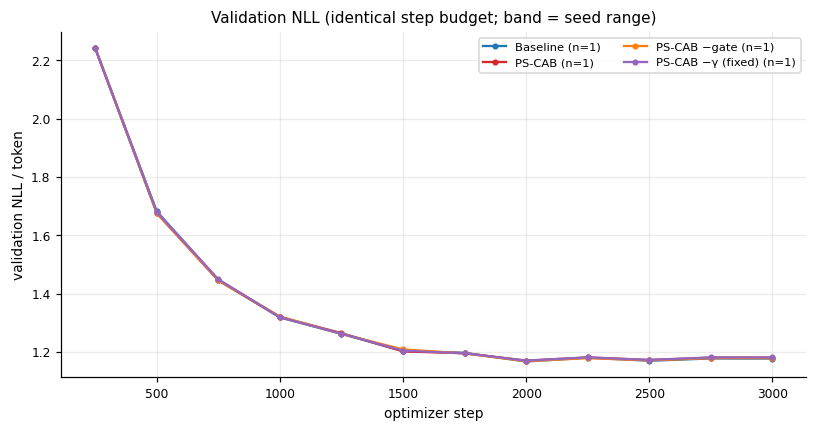

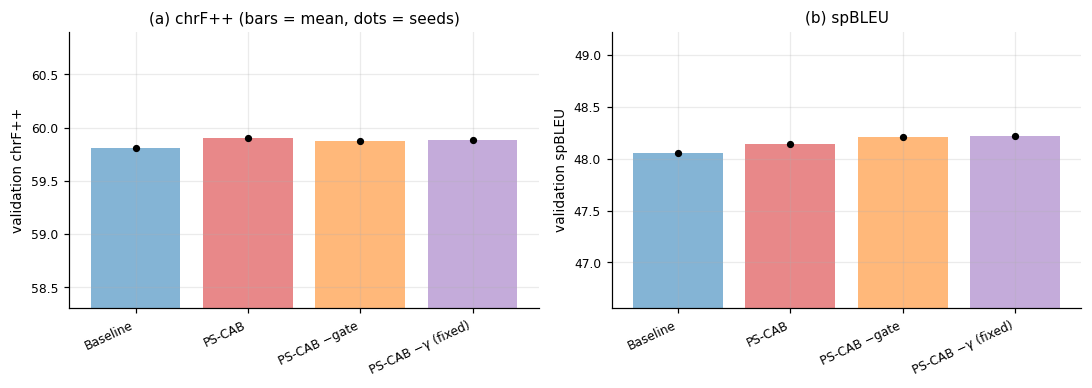

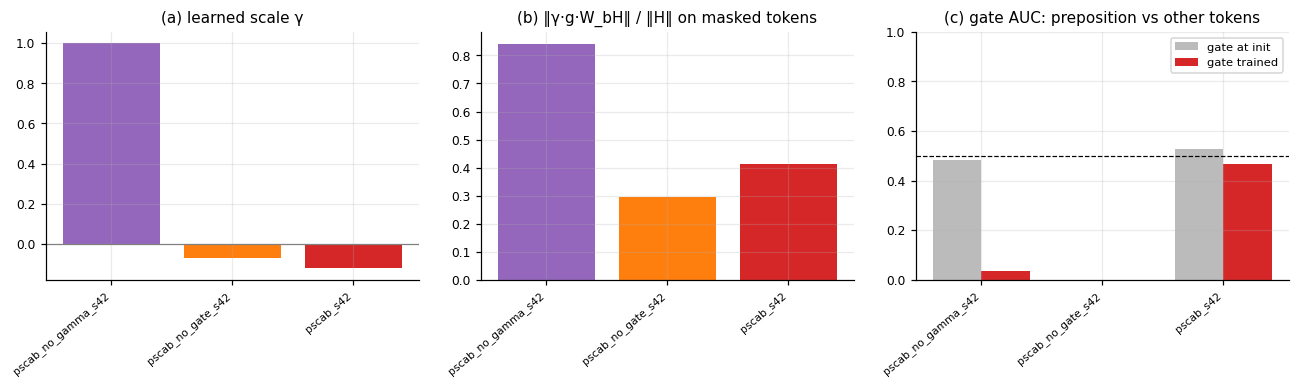

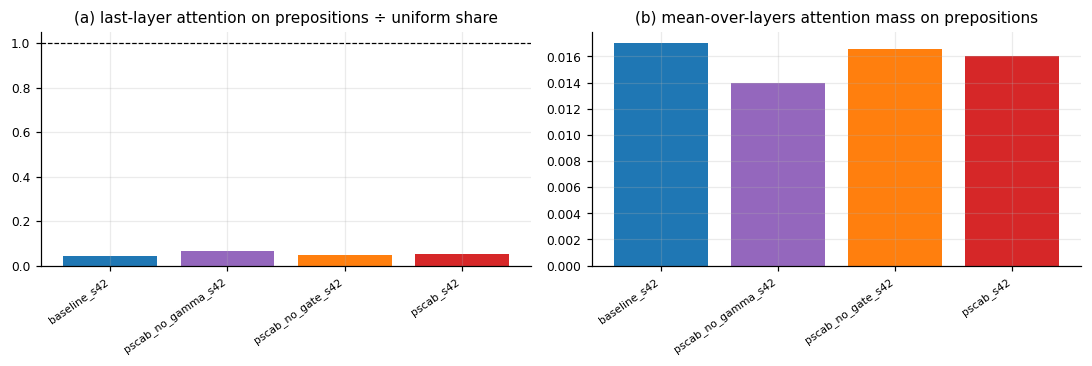

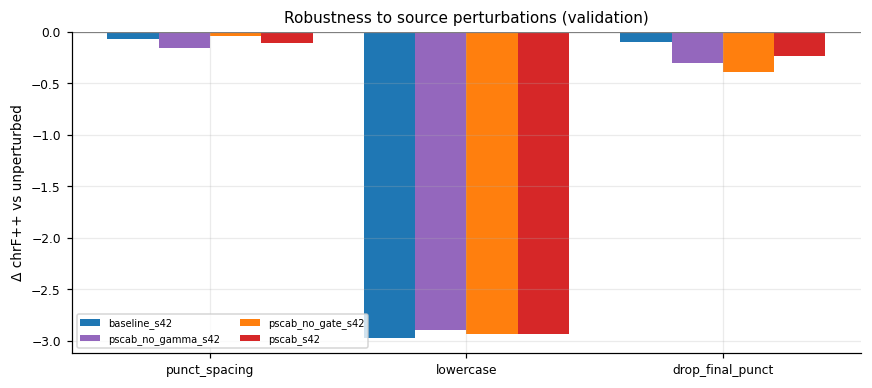

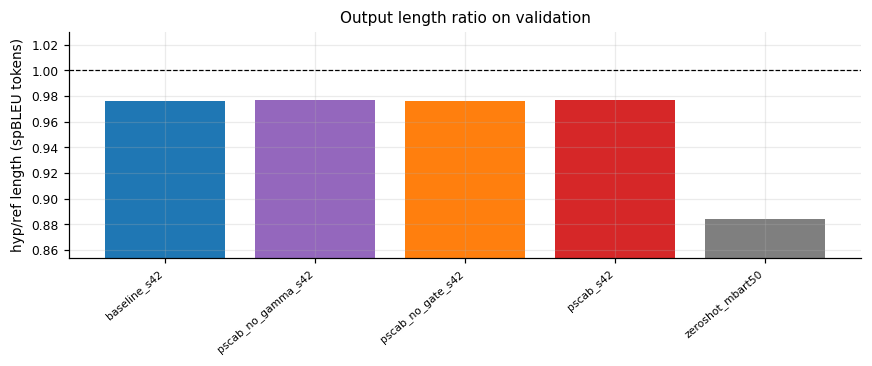

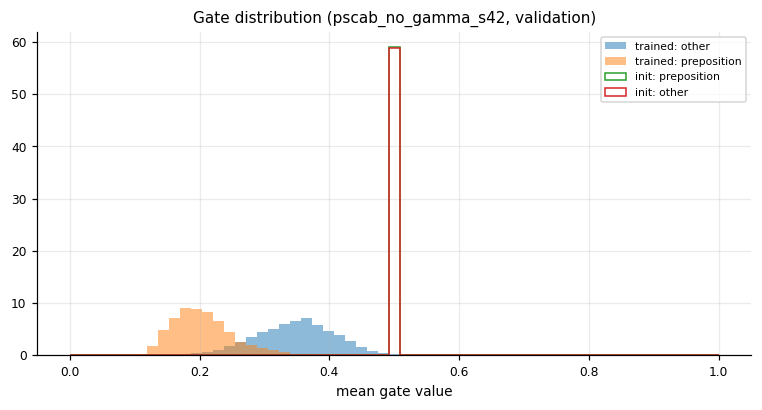

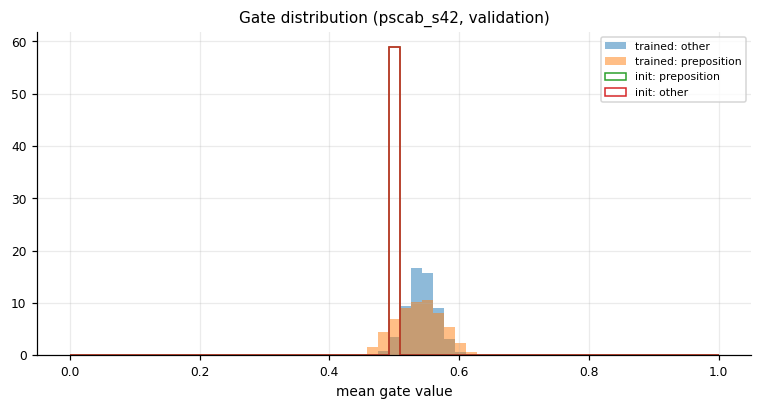


[status] main queue 4/18 complete; zero-shot done; session time left 5.4h

########################################################################
VALIDATION SUMMARY BY CONDITION (SD = N/A when only one seed)
########################################################################
     condition n_seeds seeds BLEU_mean BLEU_sd chrF++_mean chrF++_sd
      baseline       1  [42]     48.06     N/A        59.8       N/A
         pscab       1  [42]     48.15     N/A        59.9       N/A
 pscab_no_gate       1  [42]     48.21     N/A       59.87       N/A
pscab_no_gamma       1  [42]     48.22     N/A       59.88       N/A

########################################################################
CONTROL STATUS (done / pending per seed)
########################################################################
        condition     s42    s123   s2024
         baseline    done pending pending
            pscab    done pending pending
    pscab_no_gate    done pending pending
   pscab_no_gam

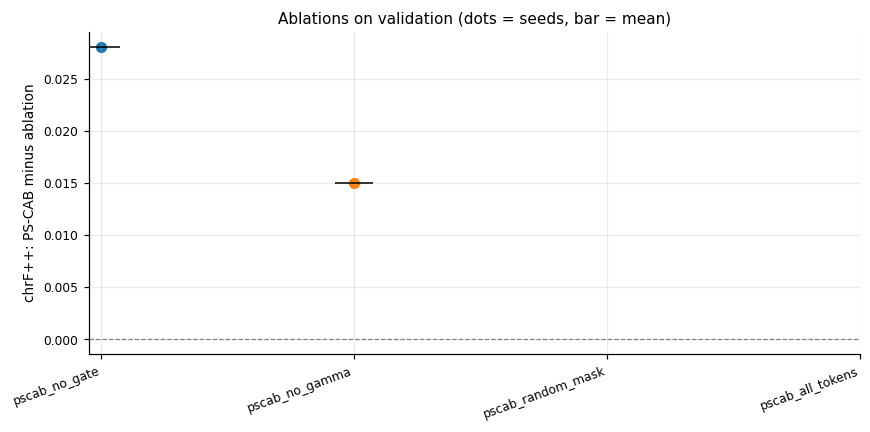

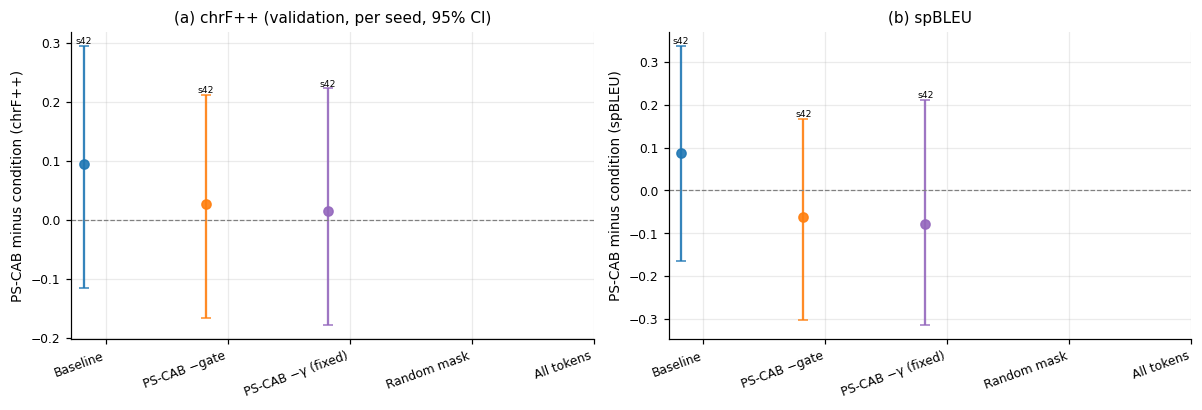


PART 2 session finished. Save the version; attach its output next session and re-run Part 1 + Part 2 until the main queue is complete, then move to Part 3.


In [4]:
"""
================================================================================
PART 2 / 3 (v3) -- ABLATIONS + EXTRA SEEDS, TWO RUNS PER KAGGLE SESSION
================================================================================
v3: every run is produced under the pinned environment (Part 1, E1). Runs from another
transformers version were moved to runs_superseded/ by Part 1 and are re-queued here
automatically (typically pscab_no_gate_s42). New: ENVIRONMENT STATUS table and the
seed-paired validation figure V_fig_paired_deltas (PS-CAB minus every other condition, per seed).

Run the Part 1 cell first (it loads the library and restores previous results; with the
completed runs restored it does NOT retrain anything). Every execution of this cell trains
the next 2 pending runs of the main queue and then prints the validation-only analysis.
Re-run it (new session, previous output attached as input) until it prints
"MAIN QUEUE COMPLETE".

What changed vs the previous Part 2 (reporting / statistics only, no training change):
  P2-1  Holm correction across ALL validation ablation comparisons (raw p + Holm-adjusted p),
        one family per metric (4 ablations x seeds completed so far).
  P2-2  Control status table: random-mask and all-token (the two controls that test the
        preposition-targeting claim) are tracked per seed and flagged until complete.
  P2-3  Seed-level pairing stays strict (pscab_s{seed} vs ablation_s{seed}); a per-ablation
        seed-consistency table is added (deltas per seed, #seeds where PS-CAB is better).
  --    SD is shown as "N/A" (never 0) when only one seed exists (Part 1's P2 table prints NaN
        for the same reason; the clean table below is the one to quote).
Queue order (unchanged, defined in Part 1):
  A: pscab_no_gate_s42 + pscab_no_gamma_s42     B: pscab_random_mask_s42 + pscab_all_tokens_s42
  C: baseline_s123 + pscab_s123                 D: baseline_s2024 + pscab_s2024
  E-H: the 4 ablations at seeds 123 and 2024 (random_mask / all_tokens are the priority there)
A run that does not fit in the remaining session time is never started or truncated.
================================================================================
"""
assert "run_next_main_runs" in globals(), "Run the Part 1 cell first in this session."

RUNS_THIS_SESSION = 2
ALPHA = 0.05


def holm_adjust(pvals: dict):
    """Holm step-down adjusted p-values (monotone, capped at 1)."""
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m, out, running = len(items), {}, 0.0
    for r, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - r) * p))
        out[k] = running
    return out


def na_df(df):
    """Display copy: NaN -> 'N/A' (used for SD with a single seed)."""
    return df.astype(object).where(df.notna(), "N/A")


def condition_summary_na():
    """Validation mean +- SD per condition; SD = N/A when n < 2 (never 0)."""
    print(f"\n{'#'*72}\nVALIDATION SUMMARY BY CONDITION (SD = N/A when only one seed)\n{'#'*72}")
    recs = [r for r in all_records("main")]
    if not recs:
        print("no completed main runs yet.")
        return
    rows = []
    for cond in CONDITIONS:
        sub = [r for r in recs if r["condition"] == cond]
        if not sub:
            continue
        row = {"condition": cond, "n_seeds": len(sub), "seeds": sorted(int(r["seed"]) for r in sub)}
        for name, key in (("BLEU", "bleu"), ("chrF++", "chrf++")):
            v = np.array([r["val_metrics"][key] for r in sub], dtype=float)
            row[f"{name}_mean"] = round(float(v.mean()), 2)
            row[f"{name}_sd"] = round(float(v.std(ddof=1)), 2) if len(v) > 1 else np.nan
        rows.append(row)
    df = pd.DataFrame(rows)
    print(na_df(df).to_string(index=False))
    save_table(na_df(df), "P2b_validation_by_condition_NA", "Validation results by condition (SD N/A for one seed)")


def control_status():
    """Which controls are done per seed. random_mask / all_tokens test the preposition-targeting claim."""
    print(f"\n{'#'*72}\nCONTROL STATUS (done / pending per seed)\n{'#'*72}")
    rows = []
    for cond in ["baseline", "pscab"] + ABLATIONS:
        row = {"condition": cond}
        for s in CFG["experiment"]["seeds"]:
            row[f"s{s}"] = "done" if run_done(f"{cond}_s{s}") else "pending"
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
    crit = [f"{c}_s{s}" for c in ("pscab_random_mask", "pscab_all_tokens") for s in CFG["experiment"]["seeds"]]
    miss = [x for x in crit if not run_done(x)]
    if miss:
        print(f"[controls] PRIORITY: do not skip these (they are what rules out the 'just extra capacity' "
              f"explanation): {miss}")
    else:
        print("[controls] random-mask and all-token controls complete for all seeds.")


def environment_status():
    print(f"\n{'#'*72}\nENVIRONMENT STATUS (all active runs must share one transformers version)\n{'#'*72}")
    rows = [{"run": r["run_id"], "kind": r["kind"], "transformers": rec_tf_version(r),
             "torch": (r.get("env") or {}).get("torch"), "python": (r.get("env") or {}).get("python"),
             "backfilled": (r.get("env") or {}).get("backfilled_from_session_log", False)} for r in all_records()]
    df = pd.DataFrame(rows)
    if len(df):
        print(df.to_string(index=False))
        vs = set(df["transformers"].astype(str))
        print("[env] OK: single transformers version" if len(vs) == 1 else f"[env] WARNING: mixed versions {vs}")
    sup = jload(f"{DIRS['analysis']}/superseded_runs.json") or []
    if sup:
        print(f"[env] superseded (kept in runs_superseded/, re-queued): {[x['run_id'] for x in sup]}")


def paired_delta_figure():
    """V_fig_paired_deltas: validation chrF++ / spBLEU of PS-CAB minus each other condition, per seed,
    with the bootstrap 95% CI of every same-seed comparison."""
    _, val, _ = load_splits()
    refs = val["te"].tolist()
    comps = []
    for s_ in CFG["experiment"]["seeds"]:
        if not run_done(f"pscab_s{s_}"):
            continue
        for other in ["baseline"] + ABLATIONS:
            if run_done(f"{other}_s{s_}"):
                comps.append((s_, other))
    if not comps:
        return
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for a, mn, lab in ((ax[0], "chrf++", "chrF++"), (ax[1], "bleu", "spBLEU")):
        M = StatMetric(mn)
        cache = {}
        for k, (s_, other) in enumerate(comps):
            for rid in (f"pscab_s{s_}", f"{other}_s{s_}"):
                if rid not in cache:
                    cache[rid] = M.stats(load_preds(rid, "val"), refs)
            res = paired_test(cache[f"pscab_s{s_}"], cache[f"{other}_s{s_}"], M, n_boot=500, n_ar=1)
            xi = (["baseline"] + ABLATIONS).index(other)
            off = (CFG["experiment"]["seeds"].index(s_) - 1) * 0.18
            a.errorbar(xi + off, res["delta"], yerr=[[res["delta"] - res["ci95_low"]], [res["ci95_high"] - res["delta"]]],
                       fmt="o", capsize=3, color=COND_COLOR[other], alpha=.9)
            a.annotate(f"s{s_}", (xi + off, res["ci95_high"]), fontsize=6, ha="center", va="bottom")
        a.axhline(0, ls="--", c="gray", lw=.8)
        a.set_xticks(range(1 + len(ABLATIONS)))
        a.set_xticklabels([COND_LABEL[c] for c in ["baseline"] + ABLATIONS], rotation=20, ha="right")
        a.set_ylabel(f"PS-CAB minus condition ({lab})")
    ax[0].set_title("(a) chrF++ (validation, per seed, 95% CI)"); ax[1].set_title("(b) spBLEU")
    save_fig("V_fig_paired_deltas")


def ablation_report():
    """Validation-only ablation view: every ablation against PS-CAB at the SAME seed, with Holm
    correction across all comparisons (one family per metric)."""
    print(f"\n{'#'*72}\nABLATION REPORT -- VALIDATION ONLY (Holm-corrected)\n{'#'*72}")
    purpose = {
        "pscab_no_gate": "Is the learned gate needed? (gate fixed to 1)",
        "pscab_no_gamma": "Is the learned global scale needed? (gamma fixed to 1, W_b zero-init)",
        "pscab_random_mask": "Does targeting PREPOSITIONS matter? (same #positions, random content tokens)",
        "pscab_all_tokens": "Is any gain just extra capacity? (module applied to every content token)",
    }
    _, val, _ = load_splits()
    refs = val["te"].tolist()
    rows, pfam = [], {"bleu": {}, "chrf++": {}}
    for seed in CFG["experiment"]["seeds"]:
        ref_id = f"pscab_s{seed}"
        if not run_done(ref_id):
            continue
        pp = load_preds(ref_id, "val")
        for abl in ABLATIONS:
            rid = f"{abl}_s{seed}"
            if not run_done(rid):
                continue
            ap = load_preds(rid, "val")
            rA, rB = jload(run_record_path(ref_id)), jload(run_record_path(rid))
            row = {"seed": seed, "ablation": abl, "tests": purpose[abl],
                   "pscab_best_step": rA["best_step"], "ablation_best_step": rB["best_step"]}
            for mn in ("bleu", "chrf++"):
                M = StatMetric(mn)
                res = paired_test(M.stats(pp, refs), M.stats(ap, refs), M, n_boot=1000, n_ar=2000)
                row[f"{mn}_pscab_minus_abl"] = res["delta"]
                row[f"{mn}_ci"] = f"[{res['ci95_low']}, {res['ci95_high']}]"
                row[f"{mn}_p_raw"] = res["p_ar"]
                pfam[mn][(seed, abl)] = res["p_ar"]
            rows.append(row)
    if not rows:
        print("no ablation run completed yet.")
        return
    for mn in ("bleu", "chrf++"):
        adj = holm_adjust({f"{s}|{a}": p for (s, a), p in pfam[mn].items()})
        for row in rows:
            k = f"{row['seed']}|{row['ablation']}"
            row[f"{mn}_p_holm"] = round(adj[k], 5)
            row[f"{mn}_sig_holm"] = bool(adj[k] < ALPHA)
    df = pd.DataFrame(rows)
    print(f"[holm] family size per metric = {len(rows)} comparisons (ablation x seed)")
    print(df.to_string(index=False))
    save_table(df, "P8_ablations_vs_pscab_validation_holm", "Ablations vs PS-CAB (validation, Holm-corrected)")

    # --- seed consistency per ablation (pairing by seed is preserved)
    cons = []
    for abl in ABLATIONS:
        sub = df[df["ablation"] == abl]
        if not len(sub):
            continue
        for mn in ("bleu", "chrf++"):
            d = sub[f"{mn}_pscab_minus_abl"].values.astype(float)
            cons.append({"ablation": abl, "metric": mn, "n_seeds": len(d),
                         "deltas_by_seed": [round(float(x), 3) for x in d],
                         "mean_delta": round(float(d.mean()), 3),
                         "sd_delta": round(float(d.std(ddof=1)), 3) if len(d) > 1 else np.nan,
                         "seeds_pscab_better": int((d > 0).sum())})
    c = pd.DataFrame(cons)
    print("\n[P8b] Seed consistency (PS-CAB minus ablation; SD N/A for one seed)\n" + na_df(c).to_string(index=False))
    save_table(na_df(c), "P8b_ablation_seed_consistency")

    print("\nReading guide (validation; confirm on test in Part 3):\n"
          "  Use the HOLM-adjusted p and the CI; raw p is shown only for transparency.\n"
          "  delta > 0 with CI excluding 0 AND Holm p < 0.05 -> the removed/changed component helps.\n"
          "  CI including 0                                   -> no evidence the component matters.\n"
          "  For random_mask / all_tokens: if PS-CAB is NOT better, the preposition-targeting claim is not supported.\n"
          "  With one seed this is a development statistic only; the claim needs all 3 seeds.")

    plt.figure(figsize=(8, 4))
    for i, abl in enumerate(ABLATIONS):
        sub = df[df["ablation"] == abl]
        if len(sub):
            plt.scatter([i] * len(sub), sub["chrf++_pscab_minus_abl"], s=40)
            plt.errorbar(i, sub["chrf++_pscab_minus_abl"].mean(), fmt="_", ms=25, color="k")
    plt.axhline(0, ls="--", c="gray", lw=.8)
    plt.xticks(range(len(ABLATIONS)), ABLATIONS, rotation=20, ha="right")
    plt.ylabel("chrF++: PS-CAB minus ablation")
    plt.title("Ablations on validation (dots = seeds, bar = mean)")
    save_fig("P_fig_ablation_deltas_validation")


run_next_main_runs(RUNS_THIS_SESSION)
environment_status()
progress_report()                 # Part 1 report incl. V_fig_* validation figures
condition_summary_na()
control_status()
ablation_report()
try:
    paired_delta_figure()
except Exception as _e:
    print(f"[figures] paired_delta_figure failed: {_e}")
print("\nPART 2 session finished. Save the version; attach its output next session and re-run Part 1 + Part 2 "
      "until the main queue is complete, then move to Part 3.")